# ****DATA PREPARATION****

<p align="center">
    <img src="../xLain-Lain/img/dp_1_1.png" alt="Data Preparation" witdh="100" height="500">
</p>

### ****DAFTAR ISI****

1. Persiapan dan Mesin Kerja
2. Keputusan Tahap 2 yang Dieksekusi Di Sini
3. Pembersihan Data (Aturan Kausal)
4. Pemulihan Kalender Hari-Kerja Penuh
5. Rekayasa Fitur Kandidat
6. Pemisahan Data Time-Series (Task 2)
7. Bukti Anti-Leakage (Task 2)
8. Transformasi Target
9. Seleksi Fitur dan Pemilihan X1-X3 (Task 1)
10. Uji Validitas Kuantitatif X1-X3 (Task 1)
11. Pemeriksaan Pada Blok Holdout 2023 - 2024
12. Pemeriksaan Pergeseran Rezim Setelah Rekayasa Fitur
13. Perakitan Keluaran dan Serah Terima ke Tahap 4

---

### ****1. Persiapan dan Mesin Kerja****

Sel pertama memuat pustaka dan konfigurasi visual yang sama dengan tahap sebelumnya. Dua sel berikutnya mendefinisikan mesin kerja yang dipakai sepanjang proyek:

1. Mesin fitur (clean_raw, restore_calendar, build_features): satu fungsi yang mengubah data mentah menjadi seluruh fitur kandidat. Ditulis sebagai fungsi murni agar dapat diuji secara otomatis: bila fungsi yang sama dijalankan pada data yang dipotong di hari $t$, hasil pada hari $t$ harus identik.
2. Mesin evaluasi (Winsorizer, make_ols, make_lgbm, make_splits, run_cv, QLIKE, uji Diebold-Mariano): memastikan semua perbandingan memakai protokol yang persis sama.

Seluruh aturan pembersihan bersifat kausal: keputusan untuk satu baris hanya bergantung pada nilai baris itu sendiri atau data sebelumnya, tidak pernah pada data sesudahnya (keputusan D05 dan D15 dari Tahap 2 Data Understanding).

In [1]:
import warnings, random, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, cwd.parent] if (p / "Dataset").exists()), cwd)
RAW_DIR, CLEAN_DIR = ROOT / "Dataset" / "Raw", ROOT / "Dataset" / "Clean"
IMG_DIR, NOTE_DIR = ROOT / "xLain-Lain" / "img", ROOT / "Catatan"
for d in (CLEAN_DIR, IMG_DIR, NOTE_DIR):
    d.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10.5,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = "#2F6DB5", "#E8833A", "#3E9B5F", "#C0392B", "#7B5EA7", "#8A8F98"

def save_fig(fig, name):
    fig.savefig(IMG_DIR / name, bbox_inches="tight", facecolor="white")
    print(f"Gambar disimpan: xLain-Lain/img/{name}")

TARGET = "Target_Volatilitas_Y"
TRAIN_END, TEST_START = pd.Timestamp("2024-12-31"), pd.Timestamp("2025-01-01")

DATA_PATH = next(p for p in [RAW_DIR / "dataset peserta.csv", RAW_DIR / "dataset_peserta.csv"] if p.exists())
raw = pd.read_csv(DATA_PATH, parse_dates=["Date"]).sort_values("Date").set_index("Date")
y = raw[TARGET]
idx_lab = y.dropna().index
print(f"Data mentah: {raw.shape[0]:,} baris | berlabel: {len(idx_lab):,} | uji (tanpa Y): {y.isna().sum():,}")

Data mentah: 4,266 baris | berlabel: 3,907 | uji (tanpa Y): 359


**Mesin Fitur**. Seluruh kode di bawah adalah satu kesatuan. Tiga hal yang membuatnya aman dari leakage:

- Tidak ada shift dengan nilai negatif dan tidak ada jendela terpusat (center=True); semua rolling, diff, pct_change, ewm, dan expanding hanya melihat ke belakang.
- Aturan pembersihan (clean_raw) memakai nilai absolut, bukan tetangga di masa depan: salah desimal terdeteksi dari USDIDR < 5.000, dan nilai macet dari |USDIDR - 9.612,45| < 3.
- Fitur kalender (hol_fixed_ahead) dihitung dari aritmetika tanggal pada lima hari kerja berikutnya dan lima tanggal libur nasional yang tetap (1 Jan, 1 Mei, 1 Jun, 17 Agu, 25 Des). Ini aturan kalender yang diketahui jauh hari, bukan informasi harga masa depan. Libur yang bergerak (mis. Idulfitri) sengaja tidak dimasukkan karena memerlukan kalender eksternal.

In [2]:
import numpy as np
import pandas as pd

EPS_LOG = 1e-4  # penstabil log untuk volatilitas (rv bisa = 0 pada pekan libur)
PLACEHOLDER_USD = 9612.45
PRICE_COLS = ["OIL", "GOLD", "USDIDR", "SP500", "IHSG", "VIX"]
MACRO_COLS = ["CPI", "BI_rate", "US_rate"]
FIXED_HOLIDAYS = {(1, 1), (5, 1), (6, 1), (8, 17), (12, 25)}    # tanggal tetap libur nasional (aturan kalender, bukan data)

def clean_raw(raw):
    d = raw.copy()
    usd = d["USDIDR"].astype(float)
    flag_a = usd < 5000     # (A) salah desimal -> x10
    flag_b = (usd - PLACEHOLDER_USD).abs() < 3      # (B) nilai macet -> NaN (diisi forward-fill setelah reindex)
    usd = usd.where(~flag_a, usd * 10)
    usd = usd.mask(flag_b)
    d["USDIDR"] = usd
    d["flag_usd_fix"] = (flag_a | flag_b).astype(int)
    return d

def restore_calendar(d):
    full = pd.bdate_range(d.index.min(), d.index.max())
    out = d.reindex(full)
    out["is_filled_row"] = (~full.isin(d.index)).astype(int)
    cols = [c for c in out.columns if c not in ("Target_Volatilitas_Y", "is_filled_row", "flag_usd_fix")]
    out[cols] = out[cols].ffill()
    out["flag_usd_fix"] = out["flag_usd_fix"].fillna(0).astype(int)
    return out

def _ret(s, k=1):
    return s.pct_change(k)

def _days_since_change(s, cap=252):
    chg = s.diff().fillna(0).ne(0).to_numpy()
    pos = np.arange(len(s), dtype=float)
    last = np.where(chg, pos, np.nan)
    last = pd.Series(last).ffill().to_numpy()
    ds = pos - last
    ds = np.where(np.isnan(ds), cap, ds)
    return pd.Series(np.minimum(ds, cap), index=s.index)

def _expanding_pct_rank(s, min_periods=66):
    x = s.to_numpy(dtype=float)
    out = np.full(len(x), np.nan)
    for i in range(min_periods - 1, len(x)):
        out[i] = np.mean(x[: i + 1] <= x[i])
    return pd.Series(out, index=s.index)

def _holiday_ahead(idx):
    cnt = np.zeros(len(idx))
    for k in range(1, 6):
        fut = idx + pd.offsets.BDay(k)
        cnt += np.array([(d.month, d.day) in FIXED_HOLIDAYS for d in fut], dtype=float)
    return pd.Series(cnt, index=idx)

def build_features(raw, include_calendar=True):
    d = restore_calendar(clean_raw(raw))
    orig_idx = raw.index
    f = pd.DataFrame(index=d.index)
    r = _ret(d["IHSG"])

    # Blok IHSG (struktur HAR, asimetri, drawdown)
    rv5, rv22, rv66 = r.rolling(5).std(), r.rolling(22).std(), r.rolling(66).std()
    f["rv5"], f["rv22"], f["rv66"] = rv5, rv22, rv66
    f["log_rv5"], f["log_rv22"], f["log_rv66"] = [np.log(x + EPS_LOG) for x in (rv5, rv22, rv66)]
    nz = r.where(r != 0)
    f["log_rv22_ex0"] = np.log(nz.rolling(22, min_periods=5).std() + EPS_LOG)
    down = (r.clip(upper=0) ** 2).rolling(22).mean()
    up = (r.clip(lower=0) ** 2).rolling(22).mean()
    f["log_semidown22"] = 0.5 * np.log(down + EPS_LOG ** 2)
    f["down_share22"] = down / (down + up + 1e-12)
    f["rv_ratio_5_22"] = f["log_rv5"] - f["log_rv22"]
    f["rv_ratio_22_66"] = f["log_rv22"] - f["log_rv66"]
    f["ihsg_ret1"], f["ihsg_absret1"] = r, r.abs()
    f["ihsg_ret5"], f["ihsg_ret22"] = _ret(d["IHSG"], 5), _ret(d["IHSG"], 22)
    f["ihsg_dd60"] = d["IHSG"] / d["IHSG"].rolling(60).max() - 1
    f["n_zero5"] = (r == 0).astype(float).rolling(5).sum()
    f["stale_today"] = (r == 0).astype(float)

    # Blok sentimen global (VIX, S&P 500)
    vix = d["VIX"]
    lv = np.log(vix)
    f["vix_log"] = lv
    f["vix_chg1"], f["vix_chg5"] = lv.diff(), lv.diff(5)
    f["vix_z126"] = (lv - lv.rolling(126, min_periods=66).mean()) / lv.rolling(126, min_periods=66).std()
    f["vix_over_rv22"] = np.log(vix / 100 / np.sqrt(252)) - f["log_rv22"]   # implied vs realized (kandidat X1)
    sp = _ret(d["SP500"])
    f["sp_ret1"], f["sp_absret1"], f["sp_ret5"] = sp, sp.abs(), _ret(d["SP500"], 5)
    f["log_sp_rv5"], f["log_sp_rv22"] = np.log(sp.rolling(5).std() + EPS_LOG), np.log(sp.rolling(22).std() + EPS_LOG)
    f["sp_dd60"] = d["SP500"] / d["SP500"].rolling(60).max() - 1

    # Blok kurs (USDIDR)
    ur = _ret(d["USDIDR"])
    f["usd_ret1"], f["usd_ret5"] = ur, _ret(d["USDIDR"], 5)
    f["log_usd_rv5"], f["log_usd_rv22"] = np.log(ur.rolling(5).std() + EPS_LOG), np.log(ur.rolling(22).std() + EPS_LOG)
    f["usd_z5"] = f["usd_ret5"] / (ur.rolling(126, min_periods=66).std() * np.sqrt(5))

    # Blok komoditas
    gr = _ret(d["GOLD"])
    f["gold_ret1"], f["gold_ret5"] = gr, _ret(d["GOLD"], 5)
    f["log_gold_rv5"], f["log_gold_rv22"] = np.log(gr.rolling(5).std() + EPS_LOG), np.log(gr.rolling(22).std() + EPS_LOG)
    oil_lvl = d["OIL"].rolling(22, min_periods=5).mean().clip(lower=10)
    oc = (d["OIL"].diff() / oil_lvl).clip(-1, 1)    # selisih relatif thd rata-rata level
    f["oil_chg1"], f["oil_chg5"] = oc, (d["OIL"].diff(5) / oil_lvl).clip(-1, 1)
    f["log_oil_rv5"], f["log_oil_rv22"] = np.log(oc.rolling(5).std() + EPS_LOG), np.log(oc.rolling(22).std() + EPS_LOG)

    # Blok suku bunga / makro
    spread = d["BI_rate"] - d["US_rate"]
    f["spread"] = spread
    f["spread_pct"] = _expanding_pct_rank(spread)
    f["bi_chg63"], f["us_chg63"] = d["BI_rate"].diff(63), d["US_rate"].diff(63)
    f["bi_days_since"] = _days_since_change(d["BI_rate"])
    f["rsi"] = f["usd_z5"] * (1 - f["spread_pct"])  # Rupiah Stress Index (kandidat X2)
    sp_rv22_lin = sp.rolling(22).std()
    f["sp_z5"] = f["sp_ret5"] / (sp_rv22_lin * np.sqrt(5) + EPS_LOG)    # guncangan S&P dalam satuan volatilitasnya sendiri
    f["ihsg_z5"] = f["ihsg_ret5"] / (rv22 * np.sqrt(5) + EPS_LOG)   # guncangan IHSG 5 hari dalam satuan volatilitas bulanan
    f["ihsg_z5_neg"] = f["ihsg_z5"].clip(upper=0)
    f["dd60_vol"] = f["ihsg_dd60"] / (rv66 * np.sqrt(60) + EPS_LOG) # drawdown dalam satuan volatilitas
    f["vrp_z126"] = (f["vix_over_rv22"] - f["vix_over_rv22"].rolling(126, min_periods=66).mean()) / f["vix_over_rv22"].rolling(126, min_periods=66).std()
    f["usd_z5_pos"] = f["usd_z5"].clip(lower=0)                                 # hanya pelemahan rupiah
    sp_mean, sp_std = spread.rolling(252, min_periods=66).mean(), spread.rolling(252, min_periods=66).std()
    carry_compress = ((sp_mean - spread) / np.maximum(sp_std, 0.25)).clip(0, 3) # penyempitan selisih bunga relatif terhadap riwayatnya
    f["carry_compress"] = carry_compress
    f["rsi2"] = f["usd_z5"] * (1 + carry_compress)
    f["global_stress"] = (f["vix_z126"] + f["usd_z5"] - f["sp_z5"]) / 3 # indeks stres gabungan (VIX naik, rupiah melemah, S&P turun)
    f["cpi_level"] = d["CPI"]   # grup opsional

    # Kalender ex-ante (aturan tanggal tetap dan tidak memakai data harga masa depan)
    if include_calendar:
        f["dow"] = d.index.dayofweek.astype(float)
        f["hol_fixed_ahead"] = _holiday_ahead(d.index)

    f["is_filled_row"] = d["is_filled_row"]
    f["flag_usd_fix"] = d["flag_usd_fix"]
    f = f.replace([np.inf, -np.inf], np.nan)
    return f.loc[f.index.isin(orig_idx)]

**Mesin Evaluasi**.

- Winsorizer mempelajari batas kuantil (0,5% dan 99,5%) hanya dari data latih, lalu menerapkannya ke validasi dan uji. Ini merupakan penanganan *bad tick* yang kami putuskan di Tahap 2 (keputusan D05) tanpa menghapus data.
- make_ols adalah Pipeline (imputasi median → *winsorizer* → *scaler* → *ridge*). Seluruh langkah praproses berada di dalam *pipeline*, sehingga pada setiap fold ia di-*fit* hanya pada data latih fold tersebut.
- purged_train_index membuang 5 baris terakhir blok latih sebelum validasi. Alasannya karna label $Y_t$ memakai harga sampai $t+5$, sehingga label lima baris terakhir latih "mengintip" harga di dalam blok validasi.
- Transformasi target log(Y + 0,001) dipakai dengan koreksi *smearing* Duan agar prediksi pada skala asli tidak bias ke bawah.
- QLIKE adalah fungsi kerugian asimetris yang menghukum *under-prediction* volatilitas lebih berat. Lantai 0,001 dipakai pada $Y$ dan prediksi karena $Y=0$ pada pekan libur.
- Uji Diebold-Mariano dengan galat baku HAC (Newey-West) dipakai karena galat prediksi horizon 5 hari berautokorelasi akibat jendela label yang tumpang tindih.

In [3]:
import numpy as np, pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.impute import SimpleImputer
import lightgbm as lgb
import statsmodels.api as sm

SEED = 42
PURGE = 5
EPS_T = 1e-3    # konstanta transformasi target log(Y + EPS_T)
EPS_Q = 1e-3    # lantai untuk QLIKE (Y dan prediksi)

class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.005, upper=0.995):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lo_ = X.quantile(self.lower).to_numpy()
        self.hi_ = X.quantile(self.upper).to_numpy()
        self.columns_ = list(X.columns)
        return self
    def transform(self, X):
        A = np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
        return pd.DataFrame(A, index=getattr(X, "index", None), columns=self.columns_)
    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns_)

def make_ols():
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("win", Winsorizer()), ("sc", StandardScaler()), ("est", Ridge(alpha=1.0))])

def make_lgbm(**kw):
    p = dict(n_estimators=250, learning_rate=0.04, num_leaves=7, min_child_samples=25, subsample=0.8, subsample_freq=1,
             colsample_bytree=0.8, reg_lambda=2.0, random_state=SEED, n_jobs=1, verbose=-1, deterministic=True, force_row_wise=True)
    p.update(kw)
    return lgb.LGBMRegressor(**p)

def qlike(y, p):
    y = np.maximum(np.asarray(y, float), EPS_Q); p = np.maximum(np.asarray(p, float), EPS_Q)
    ratio = (y / p) ** 2
    return float(np.mean(ratio - np.log(ratio) - 1))

def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return dict(RMSE=float(np.sqrt(np.mean((y - p) ** 2))), MAE=float(np.mean(np.abs(y - p))), QLIKE=qlike(y, p))

def purged_train_index(idx, val_start_pos, purge=PURGE):
    return idx[: max(val_start_pos - purge, 0)]

def make_splits(idx_lab, valid_from, latih_end="2022-12-31", cv_years=range(2016, 2023), purge=PURGE):
    idx = idx_lab[idx_lab >= valid_from]
    folds = []
    for yr in cv_years:
        v = idx[(idx >= f"{yr}-01-01") & (idx <= f"{yr}-12-31")]
        vpos = idx.get_loc(v[0])
        folds.append(dict(name=f"CV{yr}", val_year=yr, train=purged_train_index(idx, vpos, purge), val=v))
    latih = idx[idx <= latih_end]
    hold = idx[idx > latih_end]
    hpos = idx.get_loc(hold[0])
    holdout = dict(name="Holdout 2023-2024", train=purged_train_index(idx, hpos, purge), val=hold)
    return idx, folds, holdout

def fit_predict(Xtr, ytr, Xva, model_fn, target="log"):
    if target == "log":
        z = np.log(ytr.to_numpy() + EPS_T)
    elif target == "sqrt":
        z = np.sqrt(ytr.to_numpy())
    else:
        z = ytr.to_numpy()
    m = model_fn(); m.fit(Xtr, z)
    ptr, pva = m.predict(Xtr), m.predict(Xva)
    if target == "log":
        smear = np.mean(np.exp(z - ptr))
        back = lambda a: smear * np.exp(a) - EPS_T
    elif target == "sqrt":
        s = np.mean((np.sqrt(ytr.to_numpy()) - ptr) ** 2)
        back = lambda a: np.maximum(a, 0) ** 2 + s
    else:
        back = lambda a: a
    return np.maximum(back(pva), 0.0), m

def run_cv(X, y, folds, model_fn, target="log"):
    oos = []
    for f in folds:
        p, _ = fit_predict(X.loc[f["train"]], y.loc[f["train"]], X.loc[f["val"]], model_fn, target)
        oos.append(pd.Series(p, index=f["val"], name="pred"))
    return pd.concat(oos)

def summarize(y, pred, folds):
    rows = []
    for f in folds:
        rows.append({"fold": f["name"], **metrics(y.loc[f["val"]], pred.loc[f["val"]])})
    df = pd.DataFrame(rows)
    pooled = metrics(y.loc[pred.index], pred)
    return df, pooled

def dm_test(y, p_base, p_new, loss="se", maxlags=5):
    y = np.asarray(y, float)
    if loss == "se":
        d = (y - np.asarray(p_base)) ** 2 - (y - np.asarray(p_new)) ** 2
    elif loss == "ae":
        d = np.abs(y - np.asarray(p_base)) - np.abs(y - np.asarray(p_new))
    else:
        yy = np.maximum(y, EPS_Q)
        def ql(p):
            r = (yy / np.maximum(np.asarray(p), EPS_Q)) ** 2
            return r - np.log(r) - 1
        d = ql(p_base) - ql(p_new)
    res = sm.OLS(d, np.ones_like(d)).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return float(res.params[0]), float(res.tvalues[0]), float(res.pvalues[0])

### ****2. Keputusan Tahap 2 (Data Understanding) yang Dieksekusi di Sini****

Tabel berikut memuat kembali log keputusan dan menandai bagian notebook ini yang mengeksekusi masing-masing. Tidak ada keputusan yang boleh hilang tanpa jejak.

~ kata siapa ya.

In [4]:
dec = pd.read_csv(NOTE_DIR / "decision_log.csv")
where = {"D01": "Bagian 4 (uji replikasi Y)", "D02": "Bagian 7B-C (uji kausalitas, demonstrasi kebocoran)",
         "D03": "Bagian 9A (baseline naif = rv5)", "D04": "Bagian 6 dan 7C (purge)",
         "D05": "Bagian 3 (koreksi A dan B) + Winsorizer", "D06": "Bagian 5 (fitur OIL memakai selisih relatif)",
         "D07": "Bagian 5 (n_zero5, stale_today, log_rv22_ex0)", "D08": "Bagian 8 (target log + konstanta)",
         "D09": "Bagian 9B (CPI dan level suku bunga diuji dan ditolak)", "D10": "Bagian 8",
         "D11": "Bagian 5 (hanya fitur stasioner), Bagian 12", "D12": "Bagian 6 (fold bertekanan 2018, 2020, 2022)",
         "D13": "Bagian 10 (inferensi memakai n efektif)", "D14": "Bagian 9 (kontribusi marginal di atas HAR)",
         "D15": "Bagian 4", "D16": "Bagian 4 (baris label tak dapat direplikasi diberi flag)"}
dec["Dieksekusi di"] = dec["#"].map(where)
display(dec[["#", "Keputusan / tindakan", "Dieksekusi di"]].style.hide(axis="index")
        .set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

#,Keputusan / tindakan,Dieksekusi di
D01,Jadikan definisi resmi; dokumentasikan pada tahap final dan ppt,Bagian 4 (uji replikasi Y)
D02,Dilarang sebagai fitur. Hanya Y_(t-5) dan lebih lama; tambahkan uji otomatis,"Bagian 7B-C (uji kausalitas, demonstrasi kebocoran)"
D03,Implementasikan sebagai baseline resmi (persistensi),Bagian 9A (baseline naif = rv5)
D04,Purge gap >= 5 baris antara blok latih dan validasi pada semua pemisahan,Bagian 6 dan 7C (purge)
D05,"A: x10; B: NaN lalu forward-fill (keduanya aturan kausal berbasis nilai); C: tidak dihapus, winsorize return pada kuantil data latih",Bagian 3 (koreksi A dan B) + Winsorizer
D06,"Pertahankan; gunakan selisih/winsorize, bukan pct_change/log pada OIL",Bagian 5 (fitur OIL memakai selisih relatif)
D07,Buat fitur jumlah return nol/hari libur; RV memperhitungkan return nol,"Bagian 5 (n_zero5, stale_today, log_rv22_ex0)"
D08,"Bila memakai log-target, tambahkan konstanta kecil; evaluasi pada skala asli",Bagian 8 (target log + konstanta)
D09,CPI berisiko jadi penanda tahun: uji sensitivitas dengan/tanpa CPI; pakai spread suku bunga dan hari sejak perubahan,Bagian 9B (CPI dan level suku bunga diuji dan ditolak)
D10,Uji target log vs asli; laporkan RMSE/MAE pada skala asli + QLIKE,Bagian 8


### ****3. Pembersihan Data (Aturan Kasual)****

Mengapa? Tahap 2 menemukan kontaminasi pada USDIDR: 2 salah desimal (kategori A) dan nilai macet 9.612,45 yang berulang (kategori B). Tanpa koreksi, dua *return* ekstrem (-90% dan +900%) dan belasan *return* semu hingga ±23% akan mencemari semua fitur kurs dan jendela *rolling* di sekitarnya.

Mengapa aturannya harus kausal? Cara umum mendeteksi *outlier* adalah membandingkan titik dengan median tetangga di kedua sisi, tetapi itu memakai data hari berikutnya. Bila aturan seperti itu diterapkan pada data uji, ia menimbulkan leakage. Kami memakai aturan berbasis nilai dimana ia akan menghasilkan keputusan yang sama pada hari $t$ sekarang maupun ketika hari $t+1$ belum ada.

Kategori C (*bad tick* sebanyak 19 titik) tidak dihapus karena tidak ada aturan kausal yang dapat memisahkannya dari peristiwa pasar nyata. Penanganannya adalah *winsorizing* yang dipelajari dari data latih.

Baris USDIDR yang dikoreksi/ditandai : 33  (A: 2 salah desimal, B: 31 nilai macet)
|return| harian terbesar SEBELUM  :     902.9%
|return| harian terbesar SESUDAH :       5.9%
Jumlah |return| > 10% : sebelum = 16, sesudah = 0
Gambar disimpan: xLain-Lain/img/dp_2.png


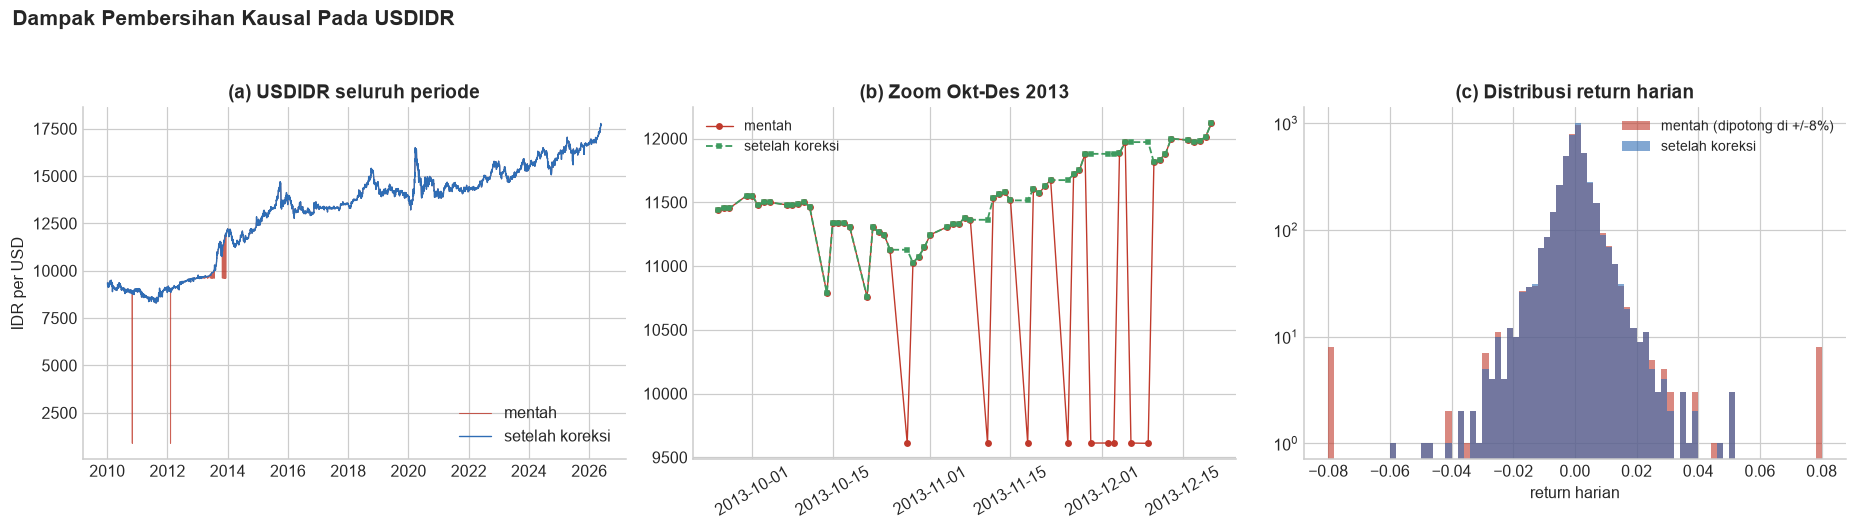

In [5]:
# pembersihan USDIDR

clean = clean_raw(raw)
n_fix = int(clean["flag_usd_fix"].sum())
usd_raw_ret   = raw["USDIDR"].pct_change()
usd_clean_ser = clean["USDIDR"].ffill()
usd_clean_ret = usd_clean_ser.pct_change()

print(f"Baris USDIDR yang dikoreksi/ditandai : {n_fix}  (A: {int((raw['USDIDR'] < 5000).sum())} salah desimal, "
      f"B: {int(((raw['USDIDR'] - PLACEHOLDER_USD).abs() < 3).sum())} nilai macet)")
print(f"|return| harian terbesar SEBELUM  : {usd_raw_ret.abs().max()*100:9.1f}%")
print(f"|return| harian terbesar SESUDAH : {usd_clean_ret.abs().max()*100:9.1f}%")
print(f"Jumlah |return| > 10% : sebelum = {(usd_raw_ret.abs() > 0.10).sum()}, sesudah = {(usd_clean_ret.abs() > 0.10).sum()}")

# setelah koreksi tidak ada return USDIDR di luar batas wajar (bad tick tetap ada: maks ~6%)
assert usd_clean_ret.abs().max() < 0.08, "Masih ada anomali besar pada USDIDR"
assert clean["flag_usd_fix"].sum() == n_fix

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
ax.plot(raw.index, raw["USDIDR"], color=RED, lw=0.7, alpha=0.8, label="mentah")
ax.plot(usd_clean_ser.index, usd_clean_ser, color=BLUE, lw=0.9, label="setelah koreksi")
ax.set_title("(a) USDIDR seluruh periode"); ax.set_ylabel("IDR per USD"); ax.legend(loc="lower right")
ax = axes[1]
z0, z1 = pd.Timestamp("2013-09-25"), pd.Timestamp("2013-12-20")
ax.plot(raw["USDIDR"][z0:z1], "o-", color=RED, ms=3.5, lw=0.9, label="mentah")
ax.plot(usd_clean_ser[z0:z1], "s--", color=GREEN, ms=3.2, lw=1.2, label="setelah koreksi")
ax.set_title("(b) Zoom Okt-Des 2013"); ax.legend(loc="upper left", fontsize=9); ax.tick_params(axis="x", rotation=30)
ax = axes[2]
bins = np.linspace(-0.08, 0.08, 81)
ax.hist(usd_raw_ret.clip(-0.08, 0.08).dropna(), bins=bins, color=RED, alpha=0.6, label="mentah (dipotong di +/-8%)")
ax.hist(usd_clean_ret.clip(-0.08, 0.08).dropna(), bins=bins, color=BLUE, alpha=0.6, label="setelah koreksi")
ax.set_yscale("log"); ax.set_title("(c) Distribusi return harian"); ax.set_xlabel("return harian"); ax.legend(fontsize=9)
fig.suptitle("Dampak Pembersihan Kausal Pada USDIDR", x=0.01, ha="left", fontweight="bold", fontsize=13.5, y=1.04)
plt.tight_layout(); save_fig(fig, "dp_2.png"); plt.show()

>INTERPRETASI

1. Koreksi menyentuh 33 baris USDIDR dmn 2 salah desimal (kategori A) dan 31 nilai macet (kategori B; 28 bernilai persis 9.612,45 dan 3 bernilai berdekatan, seperti 9.610,00).
2. Dampaknya sangat besar. *Return* harian terbesar turun dari 902,9% menjadi 5,9%, dan jumlah hari dengan |*return*| > 10% turun dari 16 menjadi 0. Sisa 5,9% adalah *bad tick* kategori C (14 Oktober 2013) yang sengaja tidak dihapus dan ditangani oleh Winsorizer.
3. Gambar 1b menunjukkan mengapa aturan ini perlu karena pada Oktober-Desember 2013, kurs mentah (merah) berulang kali jatuh ke 9.612,45 padahal kurs sebenarnya di kisaran 11.300-12.000; setelah koreksi (hijau) deretnya mulus. Panel (c) memperlihatkan ekor distribusi *return* yang tadinya "gemuk" karena data salah kini menjadi wajar.
4. Aturan bersifat kausal: keputusan tiap baris hanya bergantung pada nilai baris itu sendiri dan nilai sebelumnya (*forward-fill*), sehingga hasilnya identik ketika diterapkan pada data uji.

### ****4. Pemulihan Kalender Hari-Kerja Penuh****

Mengapa? Tahap 2 membuktikan bahwa data/lomba ini menghitung $Y$ pada kalender hari-kerja penuh dimana hari tanpa baris diperlakukan sebagai hari libur (harga sama dengan hari sebelumnya, *return* nol). Bila fitur dihitung berbasis baris, jendela "5 hari" pada sekitar celah akhir tahun menjangkau lebih dari lima hari kerja, sehingga tidak lagi selaras dengan definisi target.

Fungsi restore_calendar melakukan reindex ke seluruh hari kerja lalu *forward-fill*. Setelah fitur dihitung, hanya baris asli yang dipertahankan, sehingga data latih dan uji tetap sama dengan yang dibagikan. Sel berikut membuktikan bahwa kalender ini benar-benar selaras dengan target.

In [6]:
# uji keselarasan dgn target

cal = restore_calendar(clean)
print(f"Baris asli: {len(raw):,} -> kalender penuh: {len(cal):,}  (baris yang diisi: {int(cal['is_filled_row'].sum())})")
print("Hari yang diisi:", [d.strftime("%Y-%m-%d") for d in cal.index[cal["is_filled_row"] == 1]])

y_hat_cal = cal["IHSG"].pct_change().rolling(5).std().shift(-5).reindex(raw.index)
d_cal = (y_hat_cal - y).abs()
exact = int((d_cal[idx_lab] < 1e-9).sum())
bad_rows = d_cal[idx_lab][d_cal[idx_lab] >= 1e-9].index
print(f"\nRekonstruksi Y pada kalender penuh: cocok persis {exact:,} dari {len(idx_lab):,} baris ({exact/len(idx_lab)*100:.2f}%)")
print("Baris yang tidak dapat direplikasi (diberi flag label_tak_pasti):", [d.strftime("%Y-%m-%d") for d in bad_rows])
assert exact >= len(idx_lab) - 3, "Kalender penuh tidak selaras dengan target"

LABEL_UNCERTAIN = pd.Series(0, index=raw.index); LABEL_UNCERTAIN.loc[bad_rows] = 1

Baris asli: 4,266 -> kalender penuh: 4,275  (baris yang diisi: 9)
Hari yang diisi: ['2024-12-25', '2024-12-26', '2024-12-27', '2024-12-30', '2024-12-31', '2025-01-01', '2025-04-18', '2025-12-25', '2026-01-01']

Rekonstruksi Y pada kalender penuh: cocok persis 3,904 dari 3,907 baris (99.92%)
Baris yang tidak dapat direplikasi (diberi flag label_tak_pasti): ['2024-12-20', '2024-12-23', '2024-12-24']


>INTERPRETASI

1. Sembilan hari kerja dipulihkan: 25, 26, 27, 30, 31 Desember 2024; 1 Januari 2025; 18 April 2025; 25 Desember 2025; dan 1 Januari 2026. Total baris kalender menjadi 4.275 (dari 4.266).
2. Kalender penuh menyelaraskan fitur dengan target. Rekonstruksi $Y$ pada kalender ini cocok persis pada 3.904 dari 3.907 baris (99,92%), naik dari 99,87% pada rekonstruksi berbasis baris di Notebook 2.
3. Tiga baris sisanya (20, 23, dan 24 Desember 2024) diberi *flag* label_tak_pasti dan dipertahankan. Jendela labelnya memuat 27 Desember 2024 yang barisnya tidak dibagikan namun memiliki *return* tak nol. Dampaknya 0,08% baris dan tidak memengaruhi kesimpulan; pada Tahap 4 nanti di pemodelan akan diuji sensitivitas validasi tanpa baris-baris itu.
4. Konsekuensi bagi periode ujinya adlah Tiga hari yang hilang di periode uji (18 April 2025, 25 Desember 2025, 1 Januari 2026) kini diperlakukan sebagai hari libur dengan *return* nol, persis seperti hari libur lain yang ada pada dataset, sehingga fitur *rolling* pada data uji dihitung dengan konvensi yang sama dengan label tersembunyi.

### ****5. Rekayasa Fitur Kandidat****

Fitur dibangun dari tujuh hipotesis pada register Business Understanding (H1-H7), dengan tiga aturan:
1. stasioner (*return*, rasio, *z-score*, selisih; bukan level mentah, keputusan D11),
2. kausal (hanya data sampai hari $t$), dan
3. berdampingan dengan struktur HAR: fitur volatilitas IHSG 5, 22, dan 66 hari (log_rv5, log_rv22, log_rv66) menjadi inti (*core*). Fitur baru hanya bermakna bila menambah informasi di atas inti tersebut.

terkait rv5, nilainya identik dengan $Y_{t-5}$, yaitu satu-satunya informasi target yang sah dipakai. Kami membuktikan identitas itu secara numerik di bawah.

Tiga kelompok fitur dibuat:
1. Fitur dasar dari hipotesis: volatilitas dan asimetri IHSG, VIX, S&P 500, kurs, emas, minyak, suku bunga.
2. Fitur komposit baru (*standardized shocks*): mengukur seberapa besar suatu guncangan dalam satuan volatilitasnya sendiri, sehingga nilainya sebanding antar rezim, sifat yang penting karena periode uji lebih bergejolak. Contohnya vrp_z126, dd60_vol, ihsg_z5, sp_z5, global_stress.
3. Fitur kontrol negatif: level spread dan cpi_level sengaja disertakan untuk membuktikan (bukan sekadar menyatakan) bahwa fitur level merugikan.

In [7]:
# 5A katalog fitur

CATALOG = [
 # (fitur, keluarga, definisi, jendela_ke_belakang, hipotesis)
 ("rv5", "HAR / volatilitas IHSG", "std return harian IHSG 5 hari terakhir (= Y_(t-5))", 5, "HAR"),
 ("rv22", "HAR / volatilitas IHSG", "std return harian IHSG 22 hari", 22, "HAR"),
 ("rv66", "HAR / volatilitas IHSG", "std return harian IHSG 66 hari", 66, "HAR"),
 ("log_rv5", "HAR / volatilitas IHSG", "ln(rv5 + 1e-4)", 5, "HAR"),
 ("log_rv22", "HAR / volatilitas IHSG", "ln(rv22 + 1e-4)", 22, "HAR"),
 ("log_rv66", "HAR / volatilitas IHSG", "ln(rv66 + 1e-4)", 66, "HAR"),
 ("log_rv22_ex0", "HAR / volatilitas IHSG", "ln std 22 hari hanya pada return != 0 (membuang hari libur)", 22, "D07"),
 ("log_semidown22", "Momentum & asimetri IHSG", "ln akar rata-rata kuadrat return negatif 22 hari (downside semivariance)", 22, "H4"),
 ("down_share22", "Momentum & asimetri IHSG", "porsi varians turun terhadap total 22 hari", 22, "H4"),
 ("rv_ratio_5_22", "HAR / volatilitas IHSG", "ln(rv5) - ln(rv22)", 22, "H3"),
 ("rv_ratio_22_66", "HAR / volatilitas IHSG", "ln(rv22) - ln(rv66)", 66, "H3"),
 ("ihsg_ret1", "Momentum & asimetri IHSG", "return IHSG hari t", 1, "H4"),
 ("ihsg_absret1", "Momentum & asimetri IHSG", "|return| IHSG hari t", 1, "HAR"),
 ("ihsg_ret5", "Momentum & asimetri IHSG", "return kumulatif 5 hari", 5, "H4"),
 ("ihsg_ret22", "Momentum & asimetri IHSG", "return kumulatif 22 hari", 22, "H4"),
 ("ihsg_dd60", "Momentum & asimetri IHSG", "IHSG / maksimum 60 hari - 1 (drawdown)", 60, "H4"),
 ("n_zero5", "Kalender / stale price", "jumlah return = 0 dalam 5 hari terakhir", 5, "D07"),
 ("stale_today", "Kalender / stale price", "1 bila IHSG tidak berubah hari ini", 1, "D07"),
 ("vix_log", "Sentimen global", "ln VIX", 1, "H6"),
 ("vix_chg1", "Sentimen global", "perubahan ln VIX 1 hari", 1, "H6"),
 ("vix_chg5", "Sentimen global", "perubahan ln VIX 5 hari", 5, "H6"),
 ("vix_z126", "Sentimen global", "z-score ln VIX terhadap 126 hari terakhir", 126, "H6"),
 ("vix_over_rv22", "Sentimen global", "ln(VIX terskala harian) - ln(rv22 IHSG): proxy VRP naif", 22, "H1"),
 ("sp_ret1", "Sentimen global", "return S&P 500 hari t (ditutup sebelum IHSG buka t+1)", 1, "H6"),
 ("sp_absret1", "Sentimen global", "|return| S&P 500 hari t", 1, "H6"),
 ("sp_ret5", "Sentimen global", "return kumulatif S&P 500 5 hari", 5, "H6"),
 ("log_sp_rv5", "Sentimen global", "ln std return S&P 500 5 hari", 5, "H6"),
 ("log_sp_rv22", "Sentimen global", "ln std return S&P 500 22 hari", 22, "H6"),
 ("sp_dd60", "Sentimen global", "drawdown S&P 500 dari maksimum 60 hari", 60, "H6"),
 ("sp_z5", "Komposit baru", "return S&P 5 hari / (std 22 hari x akar 5)", 22, "H6"),
 ("usd_ret1", "Kurs", "return USDIDR hari t", 1, "H2"),
 ("usd_ret5", "Kurs", "return USDIDR 5 hari (positif = rupiah melemah)", 5, "H2"),
 ("log_usd_rv5", "Kurs", "ln std return USDIDR 5 hari", 5, "H2"),
 ("log_usd_rv22", "Kurs", "ln std return USDIDR 22 hari", 22, "H2"),
 ("usd_z5", "Komposit baru", "return USDIDR 5 hari / (std harian 126 hari x akar 5)", 126, "H2"),
 ("usd_z5_pos", "Komposit baru", "hanya bagian positif usd_z5 (pelemahan rupiah)", 126, "H2"),
 ("gold_ret1", "Komoditas", "return emas hari t", 1, "H5"),
 ("gold_ret5", "Komoditas", "return emas 5 hari", 5, "H5"),
 ("log_gold_rv5", "Komoditas", "ln std return emas 5 hari", 5, "H5"),
 ("log_gold_rv22", "Komoditas", "ln std return emas 22 hari", 22, "H5"),
 ("oil_chg1", "Komoditas", "selisih harga minyak / rata-rata level 22 hari (aman untuk harga <= 0)", 22, "H5"),
 ("oil_chg5", "Komoditas", "selisih 5 hari / rata-rata level 22 hari", 22, "H5"),
 ("log_oil_rv5", "Komoditas", "ln std oil_chg1 5 hari", 5, "H5"),
 ("log_oil_rv22", "Komoditas", "ln std oil_chg1 22 hari", 22, "H5"),
 ("spread", "Level makro (kontrol negatif)", "BI_rate - US_rate (level)", 1, "H2"),
 ("spread_pct", "Level makro (kontrol negatif)", "persentil ekspanding dari spread", 66, "H2"),
 ("bi_chg63", "Suku bunga", "perubahan BI_rate 63 hari", 63, "H7"),
 ("us_chg63", "Suku bunga", "perubahan US_rate 63 hari", 63, "H7"),
 ("bi_days_since", "Suku bunga", "hari sejak perubahan BI_rate terakhir (maks 252)", 252, "H7"),
 ("carry_compress", "Komposit baru", "penyempitan spread terhadap rata-rata 252 hari (satuan std)", 252, "H2"),
 ("rsi", "Komposit baru", "usd_z5 x (1 - spread_pct): Rupiah Stress Index awal", 66, "H2"),
 ("rsi2", "Komposit baru", "usd_z5 x (1 + carry_compress): versi perbaikan", 252, "H2"),
 ("ihsg_z5", "Komposit baru", "return IHSG 5 hari / (rv22 x akar 5): guncangan dalam satuan vol", 22, "H4"),
 ("ihsg_z5_neg", "Komposit baru", "bagian negatif ihsg_z5", 22, "H4"),
 ("dd60_vol", "Komposit baru", "drawdown 60 hari / (rv66 x akar 60): kedalaman penurunan dalam satuan vol", 66, "H4"),
 ("vrp_z126", "Komposit baru", "z-score 126 hari dari vix_over_rv22: Fear Gap", 126, "H1"),
 ("global_stress", "Komposit baru", "(vix_z126 + usd_z5 - sp_z5) / 3: stres eksternal gabungan", 126, "H1/H2/H6"),
 ("cpi_level", "Level makro (kontrol negatif)", "CPI (level; konstan per tahun)", 1, "D09"),
 ("dow", "Kalender / stale price", "hari dalam pekan (0 = Senin)", 0, "D07"),
 ("hol_fixed_ahead", "Kalender / stale price", "jumlah libur nasional bertanggal tetap pada 5 hari kerja ke depan", 0, "D07"),
]
# alif coba tambahkna hol_fix_ahead buat kalender ex-ante, karena holiday ex-ante bisa memengaruhi perilaku pasar (misal menjelang libur panjang)/nati hapus comment line ini jangan lupa
cat = pd.DataFrame(CATALOG, columns=["fitur", "keluarga", "definisi", "jendela_ke_belakang_hari", "hipotesis"])

F = build_features(raw) # seluruh fitur pada baris asli (4.266 baris)
FLAGS = ["is_filled_row", "flag_usd_fix"]
assert set(cat["fitur"]) == set(F.columns) - set(FLAGS), set(cat["fitur"]) ^ (set(F.columns) - set(FLAGS))
ALL_FEATS = list(cat["fitur"])
FAMILY = dict(zip(cat["fitur"], cat["keluarga"]))
print(f"Jumlah fitur kandidat: {len(ALL_FEATS)} | baris: {len(F):,}")
display(cat.groupby("keluarga").size().rename("jumlah").to_frame().T)

# uji rv5
last_lab = y.last_valid_index()
chk = (F["rv5"] - y.shift(5)).loc[:last_lab].dropna().abs()
print(f"\n[Identitas] rv5 vs Y_(t-5): selisih maksimum {chk.max():.2e} pada {len(chk):,} baris")
assert chk.max() < 1e-8

#
VALID_FROM = F[ALL_FEATS].dropna().index.min()
print(f"\nBaris pertama dengan semua fitur terdefinisi (VALID_FROM): {VALID_FROM:%Y-%m-%d}")
print(f"Baris pemanasan yang dibuang dari pemodelan: {(idx_lab < VALID_FROM).sum()} dari {len(idx_lab):,}")
nan_share = F[ALL_FEATS].isna().mean().sort_values(ascending=False)
print("Porsi NaN tertinggi per fitur:", nan_share.head(4).round(3).to_dict())
cat.to_csv(CLEAN_DIR / "feature_catalog.csv", index=False)

Jumlah fitur kandidat: 60 | baris: 4,266


keluarga,HAR / volatilitas IHSG,Kalender / stale price,Komoditas,Komposit baru,Kurs,Level makro (kontrol negatif),Momentum & asimetri IHSG,Sentimen global,Suku bunga
jumlah,9,4,8,11,4,3,7,11,3



[Identitas] rv5 vs Y_(t-5): selisih maksimum 7.20e-10 pada 3,902 baris

Baris pertama dengan semua fitur terdefinisi (VALID_FROM): 2010-05-05
Baris pemanasan yang dibuang dari pemodelan: 87 dari 3,907
Porsi NaN tertinggi per fitur: {'vrp_z126': 0.02, 'rv66': 0.015, 'rv_ratio_22_66': 0.015, 'log_rv66': 0.015}


>INTERPRETASI

1. Terbentuk 60 fitur kandidat dalam 9 keluarga: 11 sentimen global, 11 komposit baru, 9 volatilitas/HAR, 8 komoditas, 7 momentum/asimetri IHSG, 4 kurs, 4 kalender, 3 suku bunga, dan 3 kontrol negatif berbasis level makro.
2. Identitas $Y_{t-5}$ terbukti secara numerik: rv5 sama dengan Y yang digeser lima hari dengan selisih maksimum $7{,}2\times10^{-10}$ pada 3.902 baris. Jadi satu-satunya informasi target yang masuk ke model adalah informasi yang sah, dan ia masuk lewat harga IHSG, bukan lewat kolom Y.
3. Fitur dengan jendela terpanjang (vrp_z126, memerlukan 22 + 126 hari dengan minimum 66) baru terdefinisi penuh pada 5 Mei 2010. Sebanyak 87 dari 3.907 baris berlabel (2,2%) dibuang dari pemodelan, menyisakan 3.820 baris. Porsi nilai kosong tertinggi pada satu fitur hanya 2%.

### ****6. Pemisahan Data Time-Series (Task 2)****

Pengacakan data (random train_test_split) gak boleh. Data uji (2025+) tidak memiliki $Y$.

| Bagian | Periode | Fungsi |
|---|---|---|
| Data Latih | 2010 s.d. 2022 | Dasar seleksi fitur, pemilihan model, dan *tuning* melalui *walk-forward CV* 7 fold (validasi tahun 2016-2022, latih ekspansif) |
| Data Validasi (*holdout*) | 2023-01-01 s.d. 2024-12-24 | Blok yang tidak dipakai untuk memilih apa pun dan dipakai untuk mengukur generalisasi tanpa bias seleksi |
| Data Uji | 2025-01-02 s.d. 2026-05-22 | Tanpa $Y$; hanya menerima prediksi akhir |

Validasi 2023-2024 adalah periode paling tenang dalam sampel, sehingga *holdout* saja akan terlalu optimistis. Karena itu fold CV mencakup 2018 (tekanan pasar negara berkembang), 2020 (COVID-19), dan 2022 (siklus kenaikan suku bunga), yaitu rezim yang paling menyerupai kondisi periode uji.

Pada setiap fold, 5 baris terakhir blok latih dibuang sebelum validasi, karena label $Y_t$ memakai harga sampai $t+5$. Pada akhirnya, model final dilatih ulang pada seluruh data berlabel (Latih + Validasi) untuk memprediksi data uji.

fold,latih_awal,latih_akhir,n_latih,purge_baris,val_awal,val_akhir,n_val,mean_Y_val,%_Y_di_atas_P90
CV2016,2010-05-05,2015-12-24,1472,5,2016-01-01,2016-12-30,261,0.0076,5.0%
CV2017,2010-05-05,2016-12-23,1733,5,2017-01-02,2017-12-29,260,0.0048,0.0%
CV2018,2010-05-05,2017-12-22,1993,5,2018-01-01,2018-12-31,261,0.0090,10.0%
CV2019,2010-05-05,2018-12-24,2254,5,2019-01-01,2019-12-31,261,0.0064,0.8%
CV2020,2010-05-05,2019-12-24,2515,5,2020-01-01,2020-12-31,262,0.0126,27.5%
CV2021,2010-05-05,2020-12-24,2777,5,2021-01-01,2021-12-31,261,0.0077,1.9%
CV2022,2010-05-05,2021-12-24,3038,5,2022-01-03,2022-12-30,260,0.0072,2.7%
Holdout 2023-2024,2010-05-05,2022-12-23,3298,5,2023-01-02,2024-12-24,517,0.0062,1.5%


Uji integritas pemisahan: Lulus untuk seluruh 8 fold (urutan kronologis, tanpa irisan, purge terpenuhi)
Gambar disimpan: xLain-Lain/img/dp_3.png


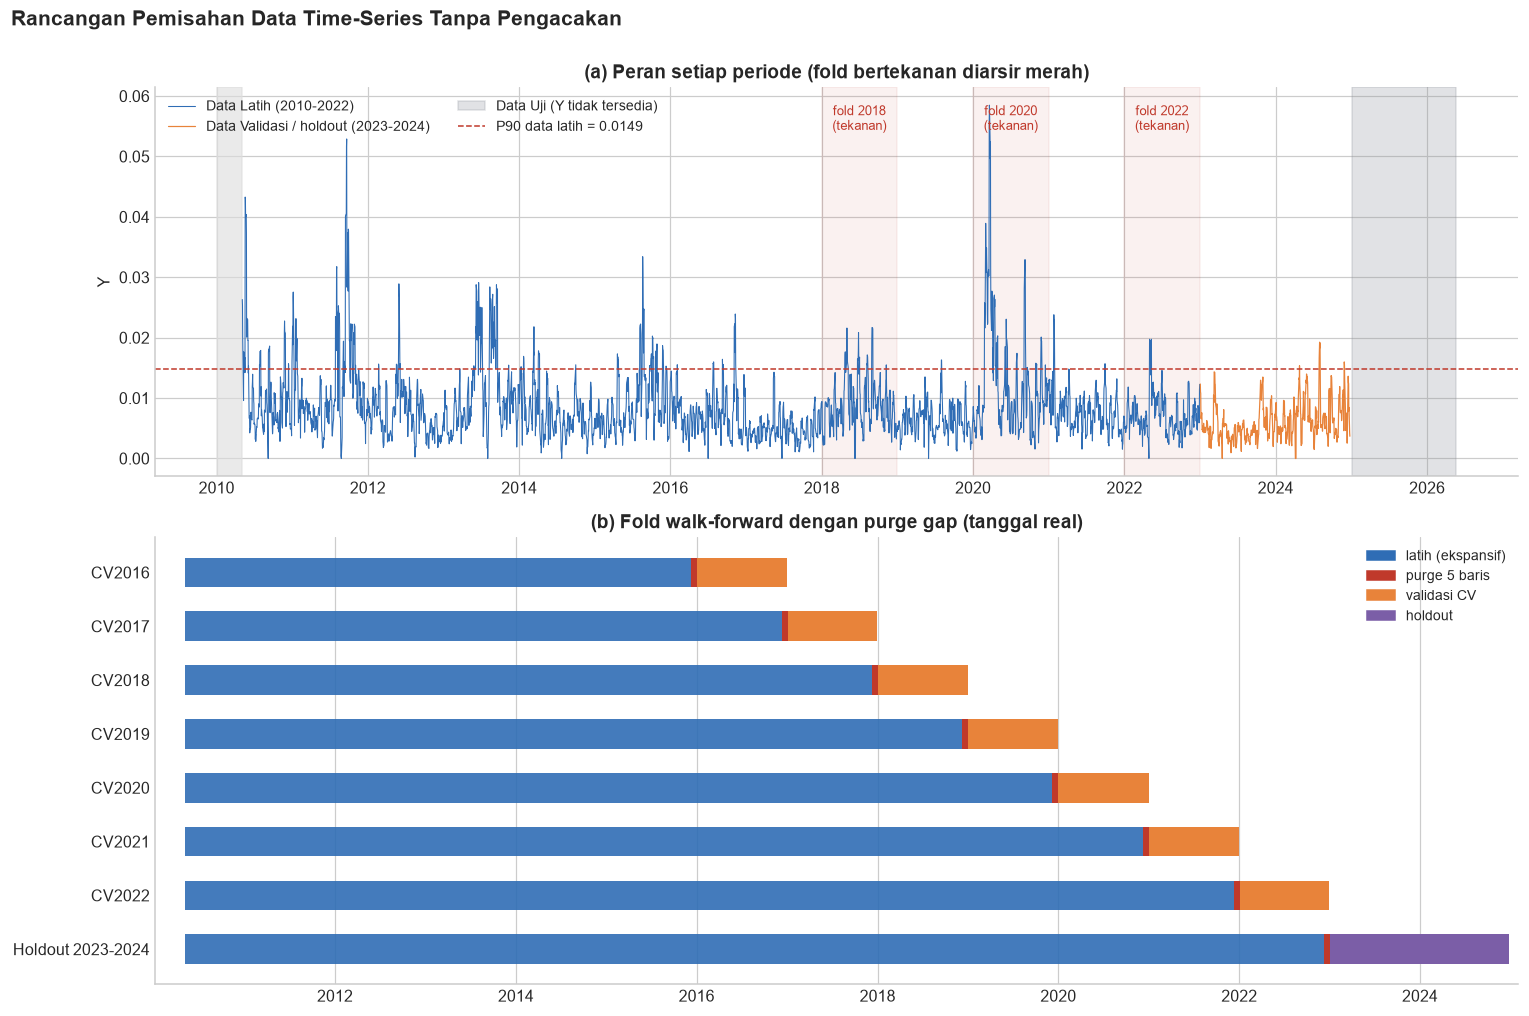

In [8]:
idx, folds, holdout = make_splits(idx_lab, VALID_FROM, latih_end="2022-12-31", cv_years=range(2016, 2023), purge=PURGE)
all_folds = folds + [holdout]
yy = y.loc[idx]
P90_LATIH = yy[yy.index <= "2022-12-31"].quantile(0.90)

rows = []
for f in all_folds:
    tr, va = f["train"], f["val"]
    rows.append({"fold": f["name"], "latih_awal": tr[0].date(), "latih_akhir": tr[-1].date(), "n_latih": len(tr),
                 "purge_baris": PURGE, "val_awal": va[0].date(), "val_akhir": va[-1].date(), "n_val": len(va),
                 "mean_Y_val": y.loc[va].mean(), "%_Y_di_atas_P90": (y.loc[va] > P90_LATIH).mean() * 100})
split_tbl = pd.DataFrame(rows)
display(split_tbl.style.format({"mean_Y_val": "{:.4f}", "%_Y_di_atas_P90": "{:.1f}%"}).hide(axis="index"))

# uji integritas
for f in all_folds:
    tr, va = f["train"], f["val"]
    assert tr.max() < va.min(), f"{f['name']}: latih tidak mendahului validasi"
    assert len(tr.intersection(va)) == 0
    assert np.busday_count(tr.max().date(), va.min().date()) >= 6, f"{f['name']}: jendela label latih menjangkau validasi"
    assert tr.is_monotonic_increasing and va.is_monotonic_increasing
print("Uji integritas pemisahan: Lulus untuk seluruh", len(all_folds), "fold (urutan kronologis, tanpa irisan, purge terpenuhi)")

fig, axes = plt.subplots(2, 1, figsize=(14, 9.2), gridspec_kw={"height_ratios": [1.0, 1.15]})
ax = axes[0]
lat = yy[yy.index <= "2022-12-31"]; hol = yy[yy.index > "2022-12-31"]
ax.plot(lat.index, lat.values, color=BLUE, lw=0.7, label="Data Latih (2010-2022)")
ax.plot(hol.index, hol.values, color=ORANGE, lw=0.8, label="Data Validasi / holdout (2023-2024)")
ax.axvspan(TEST_START, raw.index.max(), color=GREY, alpha=0.25, label="Data Uji (Y tidak tersedia)")
ax.axvspan(idx_lab.min(), VALID_FROM, color="#DDDDDD", alpha=0.6)
ax.axhline(P90_LATIH, color=RED, ls="--", lw=1, label=f"P90 data latih = {P90_LATIH:.4f}")
for yr, lab in [(2018, "2018"), (2020, "2020"), (2022, "2022")]:
    ax.axvspan(pd.Timestamp(f"{yr}-01-01"), pd.Timestamp(f"{yr}-12-31"), color=RED, alpha=0.07)
    ax.text(pd.Timestamp(f"{yr}-07-01"), yy.max() * 0.93, f"fold {lab}\n(tekanan)", ha="center", fontsize=8.5, color=RED)
ax.set_ylabel("Y"); ax.set_title("(a) Peran setiap periode (fold bertekanan diarsir merah)"); ax.legend(loc="upper left", ncol=2, fontsize=9)

ax = axes[1]
for i, f in enumerate(all_folds):
    yrow = len(all_folds) - 1 - i
    tr, va = f["train"], f["val"]
    pos = idx.get_loc(va[0])
    purge_span = idx[pos - PURGE: pos]
    ax.barh(yrow, (tr[-1] - tr[0]).days, left=mdates.date2num(tr[0]), color=BLUE, height=0.55, alpha=0.9)
    pw = max((purge_span[-1] - purge_span[0]).days + 1, 24)
    ax.barh(yrow, pw, left=mdates.date2num(va[0]) - pw, color=RED, height=0.55)
    ax.barh(yrow, (va[-1] - va[0]).days, left=mdates.date2num(va[0]), color=(PURPLE if f is holdout else ORANGE), height=0.55)
ax.set_yticks(range(len(all_folds))); ax.set_yticklabels([f["name"] for f in all_folds][::-1])
ax.xaxis_date(); ax.set_xlim(mdates.date2num(VALID_FROM) - 120, mdates.date2num(pd.Timestamp("2025-02-01")))
ax.legend(handles=[Rectangle((0, 0), 1, 1, color=BLUE, label="latih (ekspansif)"), Rectangle((0, 0), 1, 1, color=RED, label="purge 5 baris"),
                   Rectangle((0, 0), 1, 1, color=ORANGE, label="validasi CV"), Rectangle((0, 0), 1, 1, color=PURPLE, label="holdout")],
          loc="upper right", ncol=1, fontsize=9)
ax.set_title("(b) Fold walk-forward dengan purge gap (tanggal real)"); ax.grid(axis="y", visible=False)
fig.suptitle("Rancangan Pemisahan Data Time-Series Tanpa Pengacakan", x=0.01, ha="left", fontweight="bold", fontsize=13.5, y=1.0)
plt.tight_layout(); save_fig(fig, "dp_3.png"); plt.show()

splits_out = split_tbl.copy(); splits_out.to_csv(CLEAN_DIR / "splits.csv", index=False)

>INTERPRETASI

1. Struktur pemisahan. Tujuh fold CV (validasi 2016-2022) dengan data latih ekspansif dari 1.472 hingga 3.038 baris, satu *holdout* 2023-2024 (517 baris, latih 3.298 baris), dan 359 baris data uji. Seluruh uji integritas lulus: urutan kronologis, tanpa irisan, dan jarak >= 6 hari kerja antara akhir latih dan awal validasi sehingga jendela label latih tidak menjangkau validasi.
2. Fold sangat beragam, dan itu disengaja. Rata-rata $Y$ validasi berkisar dari 0,0048 (2017, tidak satu pun hari di atas P90) hingga 0,0126 (2020, 27,5% hari di atas P90). Fold 2018 (10,0%) dan 2020 mewakili rezim stres, sedangkan *holdout* 2023-2024 hanya 1,5% hari di atas P90, yakni yang paling tenang. Jadi model diuji di rezim tenang dan krisis, bukan hanya satu jenis kondisi.
3. Karena fold 2020 memuat sebagian besar kejadian volatilitas tinggi, metrik gabungan dapat dikuasai satu fold. Karena itu hasil selalu dilaporkan per fold selain gabungan, dan perbandingan memakai uji Diebold-Mariano.
4. P90 data latih adalah 0,0149 (periode 2010-05 s/d 2022), sedikit lebih tinggi dari 0,0143 pada Tahap 2 karena periode pemanasan dan blok *holdout* tidak diikutkan.

### 7. ****Bukti Anti-Leakage (Task 2)****

Studi kasus meminta tiga hal, yaitu:

1. praproses hanya di-*fit* pada data latih
2. bukti sederhana bahwa fitur hari $t$ tidak mengambil informasi hari $t+1$
3. data tidak diacak

Bgian ini memberikan bukti untuk ketiga hal tsb, ditambah dengan demonstrasi leakage yang disengaja agar terlihat bahwa ujinya benar-benar mendeteksi masalah.

#### ****7A. Praproses di-fit Hanya Pada Data Latih****

Kami melatih satu *pipeline* pada blok latih *holdout*, lalu membandingkan parameter yang dipelajari (median imputasi, batas *winsorizer*, rata-rata dan simpangan baku *scaler*) dengan nilai yang akan diperoleh bila *fit* dilakukan pada seluruh data (latih + validasi + uji). Perbedaan keduanya adalah ukuran leakage yang akan terjadi bila praproses dilakukan sebelum pemisahan.

In [9]:
# 7A

CORE = ["log_rv5", "log_rv22", "log_rv66"]
X_TEST_PROBE = ["log_rv5", "log_rv22", "log_rv66", "vrp_z126", "usd_z5", "dd60_vol"]
tr_idx, va_idx = holdout["train"], holdout["val"]
test_idx = raw.index[raw.index >= TEST_START]

pipe = make_ols()
z_tr = np.log(y.loc[tr_idx].to_numpy() + EPS_T)
pipe.fit(F.loc[tr_idx, X_TEST_PROBE], z_tr)
imp, win, sc = pipe.named_steps["imp"], pipe.named_steps["win"], pipe.named_steps["sc"]

Xtr_imp = pd.DataFrame(imp.transform(F.loc[tr_idx, X_TEST_PROBE]), columns=X_TEST_PROBE)
Xtr_win = win.transform(Xtr_imp)
# (1) scaler.mean_ harus sama dengan rata-rata data latih setelah imputasi dan winsorizing
assert np.allclose(sc.mean_, Xtr_win.mean().to_numpy()), "scaler tidak di-fit pada data latih"

# (2) Memabandingkan dengan 'fit pada seluruh data'
allrows = pd.concat([F.loc[tr_idx, X_TEST_PROBE], F.loc[va_idx, X_TEST_PROBE], F.loc[test_idx, X_TEST_PROBE]])
Xall_win = Winsorizer().fit(allrows.fillna(allrows.median())).transform(allrows.fillna(allrows.median()))
cmp_tbl = pd.DataFrame({
    "mean_scaler (dari latih, dipakai)": sc.mean_,
    "mean jika fit pada SELURUH data (salah)": Xall_win.mean().to_numpy(),
    "std_scaler (dari latih, dipakai)": sc.scale_,
    "std jika fit pada seluruh data (salah)": Xall_win.std(ddof=0).to_numpy(),
    "batas atas winsorizer (latih)": win.hi_,
    "batas atas jika fit pada seluruh data": Winsorizer().fit(allrows.fillna(allrows.median())).hi_,
}, index=X_TEST_PROBE)
cmp_tbl["selisih_mean_%_std"] = (cmp_tbl.iloc[:, 1] - cmp_tbl.iloc[:, 0]) / cmp_tbl.iloc[:, 2] * 100
display(cmp_tbl.style.format("{:.3f}"))
print("\nUji: scaler.mean_ identik dengan rata-rata data latih (lulus).")

# (3) Seberapa banyak nilai uji berada di luar batas yang dipelajari dari latih (dikembalikan ke batas oleh winsorizer)?
Xte = imp.transform(F.loc[test_idx, X_TEST_PROBE])
outside = ((Xte < win.lo_) | (Xte > win.hi_)).mean(axis=0) * 100
print("\nPersen nilai Data Uji di luar batas winsorizer dari data latih:", dict(zip(X_TEST_PROBE, outside.round(1))))

,"mean_scaler (dari latih, dipakai)",mean jika fit pada SELURUH data (salah),"std_scaler (dari latih, dipakai)",std jika fit pada seluruh data (salah),batas atas winsorizer (latih),batas atas jika fit pada seluruh data,selisih_mean_%_std
log_rv5,-4.914,-4.937,0.589,0.614,-3.279,-3.282,-3.838
log_rv22,-4.759,-4.775,0.404,0.414,-3.369,-3.454,-4.000
log_rv66,-4.704,-4.723,0.362,0.370,-3.632,-3.633,-5.177
vrp_z126,0.046,-0.010,1.190,1.188,2.952,2.918,-4.677
usd_z5,0.102,0.093,0.763,0.765,3.320,3.070,-1.224
dd60_vol,-0.432,-0.456,0.429,0.445,0.000,0.000,-5.583



Uji: scaler.mean_ identik dengan rata-rata data latih (lulus).

Persen nilai Data Uji di luar batas winsorizer dari data latih: {'log_rv5': np.float64(2.2), 'log_rv22': np.float64(0.0), 'log_rv66': np.float64(0.0), 'vrp_z126': np.float64(1.1), 'usd_z5': np.float64(0.6), 'dd60_vol': np.float64(0.3)}


>INTERPRETASI

1. Bukti formalnya, scaler.mean_ identik dengan rata-rata data latih setelah imputasi dan *winsorizing*, sehingga seluruh parameter praproses berasal dari data latih saja.
2. Besarnya leakage yang dihindari. Bila praproses di-*fit* pada seluruh data, rata-rata akan bergeser sebesar 1,2% sampai 5,6% simpangan baku (mis. dd60_vol -5,6%, log_rv66 -5,2%, vrp_z126 -4,7%), dan batas atas *winsorizer* usd_z5 berubah dari 3,32 menjadi 3,07. Pergeserannya kecil tetapi sistematis. yang penting, ia berarti informasi periode uji dan validasi akan meresap ke dalam cara data latih diskalakan.
3. Fitur rekayasa relatif aman pada data uji. Hanya 2,2% nilai log_rv5, 1,1% vrp_z126, 0,6% usd_z5, 0,3% dd60_vol, dan 0% log_rv22/log_rv66 pada data uji berada di luar batas yang dipelajari dari data latih. Bandingkan dengan level mentah pada Tahap 2, yang 35-94% hari ujinya berada di luar rentang latih.

#### ****7B. Uji Kausalitas (truncation test) dengan Kontrol Negatif****

Bila fitur pada hari $T$ benar-benar hanya bergantung pada data sampai $T$, maka menjalankan seluruh mesin fitur pada data yang dipotong di $T$ harus menghasilkan nilai yang identik untuk hari $T$ dengan hasil pada data penuh. Bila ada fitur yang memakai $t+1$, nilainya pada data terpotong akan kosong atau berbeda.

Mengapa perlu kontrol negatif? Sebuah uji yang selalu lulus tidak membuktikan apa-apa. Karena itu kami menjalankan uji yang sama pada tiga fitur yang sengaja dibocorkan: *return* hari berikutnya, $Y_{t-1}$ (memuat *return* $t+1\ldots t+4$), dan sebagai kontrol positif $Y_{t-5}$ (sah). Uji dianggap bermakna bila fitur bocor gagal dan fitur sah lulus.

40 tanggal acak ditambah 6 tanggal yang sengaja sulit: akhir data berlabel, hari setelah celah kalender (2025-01-02), setelah Jumat Agung 2025, setelah Natal 2025, dan dua hari di sekitar guncangan April 2025.

In [10]:
# 7b

def build_features_leaky(raw_):
    Fl = build_features(raw_)
    d = restore_calendar(clean_raw(raw_))
    r = d["IHSG"].pct_change()
    Fl["LEAK_ret_next"]   = r.shift(-1).reindex(Fl.index) # return hari t+1 (bocor)
    Fl["LEAK_y_lag1"]     = r.rolling(5).std().shift(-4).reindex(Fl.index) # Y_(t-1) = std(r_t .. r_(t+4)) (bocor)
    Fl["OK_y_lag5"]       = r.rolling(5).std().reindex(Fl.index)    # Y_(t-5) (sah; kontrol positif)
    return Fl

def causality_test(builder, raw_, dates, full=None):
    full = builder(raw_) if full is None else full
    fails = {c: 0 for c in full.columns}
    for T in dates:
        part = builder(raw_.loc[:T])
        a, b = part.loc[T], full.loc[T]
        for c in full.columns:
            if not np.isclose(a[c], b[c], rtol=1e-9, atol=1e-12, equal_nan=True):
                fails[c] += 1
    return pd.Series(fails, name="jumlah_tanggal_gagal")

rng = np.random.default_rng(SEED)
rand_dates = list(rng.choice(raw.index[300:-8], size=40, replace=False))
special = [pd.Timestamp(d) for d in ["2024-12-24", "2025-01-02", "2025-04-08", "2025-04-21", "2025-12-26", "2026-01-02"]]
T_dates = sorted(set(pd.to_datetime(rand_dates)) | set(special))
assert all(d in raw.index for d in T_dates)

t0 = time.time()
res_clean = causality_test(build_features, raw, T_dates)
res_leaky = causality_test(build_features_leaky, raw, T_dates)
print(f"Tanggal uji: {len(T_dates)} | waktu: {time.time()-t0:.1f} detik\n")

summary = pd.DataFrame({
    "kelompok": ["Seluruh fitur resmi (%d fitur)" % len(ALL_FEATS), "LEAK_ret_next (return t+1)", "LEAK_y_lag1 (Y_(t-1))", "OK_y_lag5 (Y_(t-5), kontrol positif)"],
    "tanggal_gagal_maks": [int(res_clean.max()), int(res_leaky["LEAK_ret_next"]), int(res_leaky["LEAK_y_lag1"]), int(res_leaky["OK_y_lag5"])],
    "dari_total_tanggal": len(T_dates),
    "hasil": ["LULUS" if res_clean.max() == 0 else "GAGAL",
              "GAGAL (terdeteksi)" if res_leaky["LEAK_ret_next"] > 0 else "tidak terdeteksi",
              "GAGAL (terdeteksi)" if res_leaky["LEAK_y_lag1"] > 0 else "tidak terdeteksi",
              "LULUS" if res_leaky["OK_y_lag5"] == 0 else "GAGAL"],
})
display(summary.style.hide(axis="index"))
assert res_clean.max() == 0, f"Ada fitur yang melanggar kausalitas: {res_clean[res_clean > 0].to_dict()}"
assert res_leaky["LEAK_ret_next"] > 0 and res_leaky["LEAK_y_lag1"] > 0 and res_leaky["OK_y_lag5"] == 0

F_full = build_features(raw)
pert_fail = 0
for T in [pd.Timestamp("2018-06-15"), pd.Timestamp("2020-03-12"), pd.Timestamp("2024-08-05"), pd.Timestamp("2025-04-08")]:
    rp = raw.copy()
    after = rp.index > T
    rp.loc[after, ["OIL", "GOLD", "SP500", "IHSG", "VIX"]] *= rng.uniform(0.6, 1.6, size=(after.sum(), 5))
    Fp = build_features(rp)
    a, b = Fp.loc[:T, ALL_FEATS], F_full.loc[:T, ALL_FEATS]
    ok = np.allclose(a.to_numpy(float), b.to_numpy(float), rtol=1e-9, atol=1e-12, equal_nan=True)
    pert_fail += (not ok)
print(f"\n[Uji perturbasi] 4 tanggal; seluruh harga Setelah T dikalikan faktor acak 0,6-1,6; fitur pada dan sebelum T berubah: {'TIDAK (LULUS)' if pert_fail == 0 else 'YA (GAGAL)'}")
assert pert_fail == 0

Tanggal uji: 46 | waktu: 13.0 detik



kelompok,tanggal_gagal_maks,dari_total_tanggal,hasil
Seluruh fitur resmi (60 fitur),0,46,LULUS
LEAK_ret_next (return t+1),46,46,GAGAL (terdeteksi)
LEAK_y_lag1 (Y_(t-1)),46,46,GAGAL (terdeteksi)
"OK_y_lag5 (Y_(t-5), kontrol positif)",0,46,LULUS



[Uji perturbasi] 4 tanggal; seluruh harga Setelah T dikalikan faktor acak 0,6-1,6; fitur pada dan sebelum T berubah: TIDAK (LULUS)


>INTERPRETASI

1. Seluruh 60 fitur lulus pada seluruh 46 tanggal uji (0 kegagalan), termasuk enam tanggal yang sengaja sulit (akhir data berlabel, hari setelah celah kalender, setelah Jumat Agung 2025, setelah Natal 2025, dan sekitar guncangan April 2025).
2. Ujinya terbukti memiliki daya. *Return* hari berikutnya dan $Y_{t-1}$ yang sengaja dibocorkan gagal pada 46 dari 46 tanggal, sedangkan $Y_{t-5}$ (kontrol positif, sah) lulus pada 46 dari 46. Uji yang membedakan keduanya dengan tegas adalah uji yang bermakna.
3. Uji perturbasi mengonfirmasi dari arah berlawanan. Ketika seluruh harga setelah hari $T$ dikalikan faktor acak 0,6-1,6, tidak satu pun fitur pada atau sebelum $T$ berubah (4 tanggal, termasuk 8 April 2025).

#### ****7C. Seberapa Penting Purge, dan Seperti Apa Kebocoran Leakage Lag Target****

Berikut adlah dua demonstrasi kuantitatif yang melengkapi bukti di atas:

1. *Purge* vs tanpa *purge*. Kami menjalankan CV yang identik dua kali dimana dengan 5 baris *purge* dan tanpa *purge* (0 baris). Blok validasinya sama persis. Hanya blok latih yang berbeda.
2. Kebocoran *lag* target. Kami menambahkan $Y_{t-1}$ (bocor) dan $Y_{t-5}$ (sah) sebagai fitur. Bila galat turun drastis dengan $Y_{t-1}$, itu bukan kemampuan model, melainkan informasi masa depan yang tidak tersedia saat prediksi nyata.

purge_baris,model,RMSE,MAE,QLIKE
5,OLS (HAR+X),0.00427,0.00307,0.4793
5,LightGBM (HAR+X),0.00425,0.00308,0.4919
0,OLS (HAR+X),0.00427,0.00307,0.4788
0,LightGBM (HAR+X),0.00424,0.00308,0.4900


model,LightGBM,OLS
varian,,
Bocor: + Y_(t-1),0.00263,0.00371
Sah: + Y_(t-5),0.00430,0.00414
Sah: HAR + X1-X3,0.00425,0.00427


Gambar disimpan: xLain-Lain/img/dp_4.png


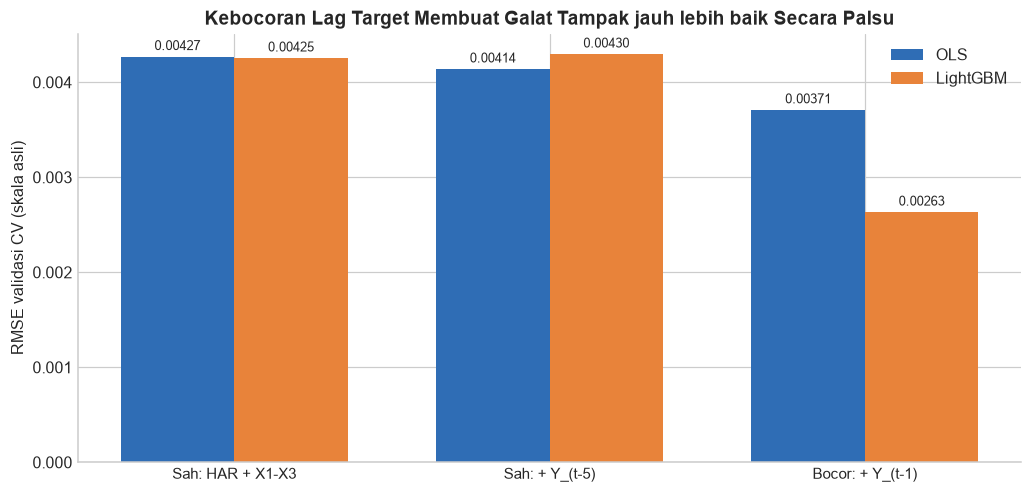

In [11]:
# 7c

CORE_X = CORE + ["vrp_z126", "usd_z5", "dd60_vol"]
rows = []
for purge in (5, 0):
    _, fo, ho = make_splits(idx_lab, VALID_FROM, purge=purge)
    for name, mf in [("OLS (HAR+X)", make_ols), ("LightGBM (HAR+X)", make_lgbm)]:
        p = run_cv(F[CORE_X].loc[idx], yy, fo, mf, "log")
        m = metrics(yy.loc[p.index], p)
        rows.append({"purge_baris": purge, "model": name, **m})
purge_tbl = pd.DataFrame(rows)
display(purge_tbl.style.format({"RMSE": "{:.5f}", "MAE": "{:.5f}", "QLIKE": "{:.4f}"}).hide(axis="index"))

# ---- Kebocoran lag target ----
y_lag1 = y.shift(1).loc[idx] # Y_(t-1): memuat return t+1..t+4 (bocor)
y_lag5 = y.shift(5).loc[idx] # Y_(t-5): sah (setara rv5)
variants = {
    "Sah: HAR + X1-X3": F[CORE_X].loc[idx],
    "Sah: + Y_(t-5)":   F[CORE_X].loc[idx].assign(Y_lag5=y_lag5),
    "Bocor: + Y_(t-1)": F[CORE_X].loc[idx].assign(Y_lag1=y_lag1),
}
leak_rows = []
for name, X in variants.items():
    for mname, mf in [("OLS", make_ols), ("LightGBM", make_lgbm)]:
        p = run_cv(X, yy, folds, mf, "log")
        leak_rows.append({"varian": name, "model": mname, **metrics(yy.loc[p.index], p)})
leak_tbl = pd.DataFrame(leak_rows)
display(leak_tbl.pivot(index="varian", columns="model", values="RMSE").style.format("{:.5f}"))

fig, ax = plt.subplots(figsize=(9.5, 4.6))
pv = leak_tbl.pivot(index="varian", columns="model", values="RMSE").loc[list(variants.keys())]
xpos = np.arange(len(pv)); wd = 0.36
b1 = ax.bar(xpos - wd/2, pv["OLS"], wd, color=BLUE, label="OLS"); b2 = ax.bar(xpos + wd/2, pv["LightGBM"], wd, color=ORANGE, label="LightGBM")
for bars in (b1, b2):
    for b in bars: ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.00007, f"{b.get_height():.5f}", ha="center", fontsize=8.8)
ax.set_xticks(xpos); ax.set_xticklabels(pv.index, fontsize=10); ax.set_ylabel("RMSE validasi CV (skala asli)")
ax.set_title("Kebocoran Lag Target Membuat Galat Tampak jauh lebih baik Secara Palsu"); ax.legend()
plt.tight_layout(); save_fig(fig, "dp_4.png"); plt.show()

>INTERPRETASI

1. *Purge* nyaris tidak mengubah angka pada rancangan ini, dan kami melaporkannya apa adanya. RMSE OLS 0,00427 baik dengan maupun tanpa *purge*; LightGBM 0,00425 vs 0,00424. QLIKE berbeda kurang dari 0,5%. Alasannya masuk akal karena pada fold tahunan, yang terdampak hanya 5 baris di tepi blok latih dari ribuan baris, dan model berkapasitas rendah (3-7 fitur) nyaris tidak dapat memanfaatkan label yang bocor. Kami tetap menerapkannya karena biayanya nol dan secara metodologis wajib untuk label yang tumpang tindih. Dampaknya akan lebih besar pada blok validasi yang lebih pendek atau model berkapasitas tinggi.
2. Kebocoran *lag* target menghasilkan perbaikan palsu yang besar. Menambahkan $Y_{t-1}$ menurunkan RMSE LightGBM dari 0,00425 menjadi 0,00263 (-38%) dan OLS dari 0,00427 menjadi 0,00371 (-13%). Itu *return* hari $t+1\ldots t+4$ yang belum terjadi pada saat prediksi.
3. Lag yang sah tidak menambah apa-apa. Menambahkan $Y_{t-5}$ memberi RMSE 0,00414 (OLS) dan 0,00430 (LightGBM), praktis sama dengan model tanpanya, karena informasinya sudah terkandung dalam log_rv5.

### ****8. Transformsi Target****

Mengapa? Tahap 2 menunjukkan $Y$ sangat condong ke kanan (*skewness* 2,6) tetapi hampir simetris pada skala logaritma, dengan 16 nilai nol akibat jendela libur. Kami membandingkan tiga bentuk target pada protokol CV yang sama: skala asli, akar kuadrat, dan $\ln(Y+0{,}001)$ dengan koreksi *smearing*. Seluruh metrik dihitung pada skala asli agar adil.

In [12]:
# perbandingan bentuk target

rows = []
for tgt in ["raw", "sqrt", "log"]:
    for mname, mf in [("OLS (HAR inti)", make_ols), ("LightGBM (HAR inti)", make_lgbm)]:
        p = run_cv(F[CORE].loc[idx], yy, folds, mf, tgt)
        rows.append({"target": {"raw": "Y (asli)", "sqrt": "akar Y", "log": "ln(Y + 0,001)"}[tgt], "model": mname, **metrics(yy.loc[p.index], p)})
tgt_tbl = pd.DataFrame(rows)
display(tgt_tbl.pivot(index="target", columns="model", values="RMSE").style.format("{:.5f}").set_caption("RMSE (skala asli)"))
display(tgt_tbl.pivot(index="target", columns="model", values="QLIKE").style.format("{:.4f}").set_caption("QLIKE"))
best_t = tgt_tbl.loc[tgt_tbl.groupby("model")["QLIKE"].idxmin(), ["model", "target", "QLIKE"]]
print("Target dengan QLIKE terbaik per model:"); display(best_t.style.hide(axis="index").format({"QLIKE": "{:.4f}"}))

model,LightGBM (HAR inti),OLS (HAR inti)
target,,
Y (asli),0.00488,0.00481
akar Y,0.00485,0.00476
"ln(Y + 0,001)",0.00486,0.00472


model,LightGBM (HAR inti),OLS (HAR inti)
target,,
Y (asli),0.5746,0.6519
akar Y,0.5672,0.5559
"ln(Y + 0,001)",0.5731,0.5482


Target dengan QLIKE terbaik per model:


model,target,QLIKE
LightGBM (HAR inti),akar Y,0.5672
OLS (HAR inti),"ln(Y + 0,001)",0.5482


>INTERPRETASI

1. Pilihan bentuk target hanya sedikit memengaruhi RMSE (OLS 0,00481 / 0,00476 / 0,00472 untuk skala asli / akar / log; LightGBM 0,00488 / 0,00485 / 0,00486). Pada QLIKE, yang lebih peka terhadap ekor, perbedaannya lebih jelas untuk OLS: 0,652 (asli) → 0,556 (akar) -> 0,548 (log), yaitu perbaikan 16% dengan transformasi log.
2. Memakai $\ln(Y+0{,}001)$ dengan koreksi *smearing*. Alasannya, karena terbaik untuk OLS, selisihnya dengan akar kuadrat pada LightGBM tidak bermakna (QLIKE 0,567 vs 0,573), bentuk logaritma memberi interpretasi multiplikatif yang cocok untuk volatilitas (SHAP pada skala log berarti "fitur ini menaikkan volatilitas sekian persen"), dan satu bentuk untuk semua model menyederhanakan perbandingan. Bentuk ini diuji ulang pada Tahap 4 setelah *tuning*.
3. Semua metrik dihitung pada skala asli, sehingga pilihan transformasi tidak memberi keuntungan semu.

### ****9. Seleksi Fitur dan Pemilihan X1 - X3 (Task 1)****

Prinsip pengukurannya adalah kontribusi marginal, bukan korelasi.

Pada Tahap 2, korelasi univariat didominasi oleh volatilitas IHSG sendiri. Namun fitur yang berkorelasi tinggi dengan $Y$ belum tentu menambah informasi bila volatilitas IHSG sudah ada di model. Karena itu setiap kandidat diuji dengan pertanyaan yang adil, yaitu seberapa banyak galat validasi turun bila fitur itu ditambahkan ke struktur HAR (log_rv5, log_rv22, log_rv66)?

Pengujian dilakukan pada dua jenis model agar kesimpulan tidak bergantung pada satu algoritma: OLS/ridge (linear, mudah ditafsir) dan LightGBM (non-linear, kandidat model utama). Ukuran yang dilaporkan: perubahan RMSE (%), perubahan QLIKE, *p-value* Diebold–Mariano dengan galat baku HAC, dan jumlah fold yang membaik. Seluruh seleksi memakai fold CV 2016–2022 saja; *holdout* 2023-2024 tidak disentuh.

#### ****9A. Titik Acuan****

Sebelum menilai kandidat, kita perlu tahu seberapa baik model sederhana:
1. baseline naif studi kasus (volatilitas 5 hari terakhir), dan 
2. HAR inti (hanya tiga fitur volatilitas IHSG).

In [13]:
# 9a

def pooled(p): return metrics(yy.loc[p.index], p)
naive = pd.concat([F.loc[f["val"], "rv5"] for f in folds]).rename("pred")
p_har_ols  = run_cv(F[CORE].loc[idx], yy, folds, make_ols,  "log")
p_har_lgbm = run_cv(F[CORE].loc[idx], yy, folds, make_lgbm, "log")
base_tbl = pd.DataFrame({"Naif (rv5 = Y_(t-5))": pooled(naive), "HAR inti, OLS": pooled(p_har_ols), "HAR inti, LightGBM": pooled(p_har_lgbm)}).T
base_tbl["RMSE vs naif"] = (base_tbl["RMSE"] / base_tbl.loc["Naif (rv5 = Y_(t-5))", "RMSE"] - 1) * 100
display(base_tbl.style.format({"RMSE": "{:.5f}", "MAE": "{:.5f}", "QLIKE": "{:.4f}", "RMSE vs naif": "{:+.1f}%"}))
p_,t_,pv_ = dm_test(yy.loc[p_har_ols.index], naive.loc[p_har_ols.index], p_har_ols, "se")
print(f"Diebold-Mariano, HAR-OLS vs naif (galat kuadrat): selisih rata-rata {p_:.2e}, t = {t_:.2f}, p = {pv_:.4f}")

,RMSE,MAE,QLIKE,RMSE vs naif
Naif (rv5 = Y_(t-5)),0.00556,0.00398,2.2367,+0.0%
"HAR inti, OLS",0.00472,0.00320,0.5482,-15.0%
"HAR inti, LightGBM",0.00486,0.00335,0.5731,-12.6%


Diebold-Mariano, HAR-OLS vs naif (galat kuadrat): selisih rata-rata 8.60e-06, t = 2.89, p = 0.0039


>INTERPRETASI

1. Baseline naif (volatilitas 5 hari terakhir) memiliki RMSE 0,00556 dan MAE 0,00398 pada CV walk-forward. QLIKE-nya sangat besar (2,24) karena pada pekan libur rv5 = 0 sehingga naif memprediksi volatilitas nol, dan QLIKE menghukum *under-prediction* ekstrem. Ini keterbatasan nyata baseline naif.
2. HAR inti dengan OLS mengalahkan naif: RMSE 0,00472 (-15,0%), MAE 0,00320, QLIKE 0,548. Uji Diebold-Mariano memberi $t=2{,}89$, $p=0{,}004$, sehingga keunggulan ini signifikan secara statistik.
3. LightGBM pada HAR inti sedikit lebih buruk dari OLS (0,00486, -12,6%). Wajar dimana tiga fitur yang halus dan hampir linear tidak memerlukan model non-linear; keunggulan LightGBM baru diharapkan ketika ada fitur yang efeknya berbentuk ambang.
4. Titik acuan ini menjadi garis dasar untuk seluruh klaim berikutnya dimana setiap fitur baru harus mengalahkan HAR inti.

#### ****9B. Penyaringan Seluruh Kandidat****

Setiap fitur kandidat ditambahkan satu per satu ke inti HAR. Hasilnya diurutkan menurut perbaikan RMSE pada LightGBM. Fitur level spread dan cpi_level sengaja diikutkan sebagai kontrol negatif dimana bila uji nya sahih, keduanya harus merugikan.

Penyaringan 54 kandidat x 2 model x 7 fold selesai dalam 29 detik


,keluarga,OLS_dRMSE%,OLS_DM_p,OLS_fold_membaik,LGBM_dRMSE%,LGBM_DM_p,LGBM_fold_membaik,LGBM_dQLIKE
fitur,,,,,,,,
dd60_vol,Komposit baru,-4.25,0.070,4,-7.42,0.038,7,-0.053
ihsg_ret22,Momentum & asimetri IHSG,-2.70,0.114,4,-6.62,0.033,4,-0.049
global_stress,Komposit baru,-4.91,0.031,5,-6.48,0.009,5,-0.057
ihsg_ret5,Momentum & asimetri IHSG,-3.96,0.069,7,-6.20,0.020,6,-0.047
ihsg_z5_neg,Komposit baru,-5.58,0.067,5,-6.12,0.016,6,-0.048
ihsg_z5,Komposit baru,-2.84,0.039,7,-6.10,0.014,6,-0.042
ihsg_dd60,Momentum & asimetri IHSG,-2.97,0.352,6,-5.62,0.110,6,-0.044
vrp_z126,Komposit baru,-3.29,0.063,6,-4.97,0.003,6,-0.050
sp_ret5,Sentimen global,-2.36,0.132,4,-4.75,0.025,5,-0.043



Kandidat yang merugikan LightGBM (dRMSE > +1%):


,keluarga,OLS_dRMSE%,OLS_DM_p,OLS_fold_membaik,LGBM_dRMSE%,LGBM_DM_p,LGBM_fold_membaik,LGBM_dQLIKE
fitur,,,,,,,,
log_sp_rv22,Sentimen global,-0.26,0.467,3,+2.33,0.042,3,+0.019
log_usd_rv22,Kurs,-0.01,0.892,4,+3.76,0.087,3,+0.077
cpi_level,Level makro (kontrol negatif),+0.77,0.320,5,+5.38,0.018,3,+0.113
spread,Level makro (kontrol negatif),+0.77,0.132,4,+9.76,0.000,2,+0.353


Gambar disimpan: xLain-Lain/img/dp_5.png


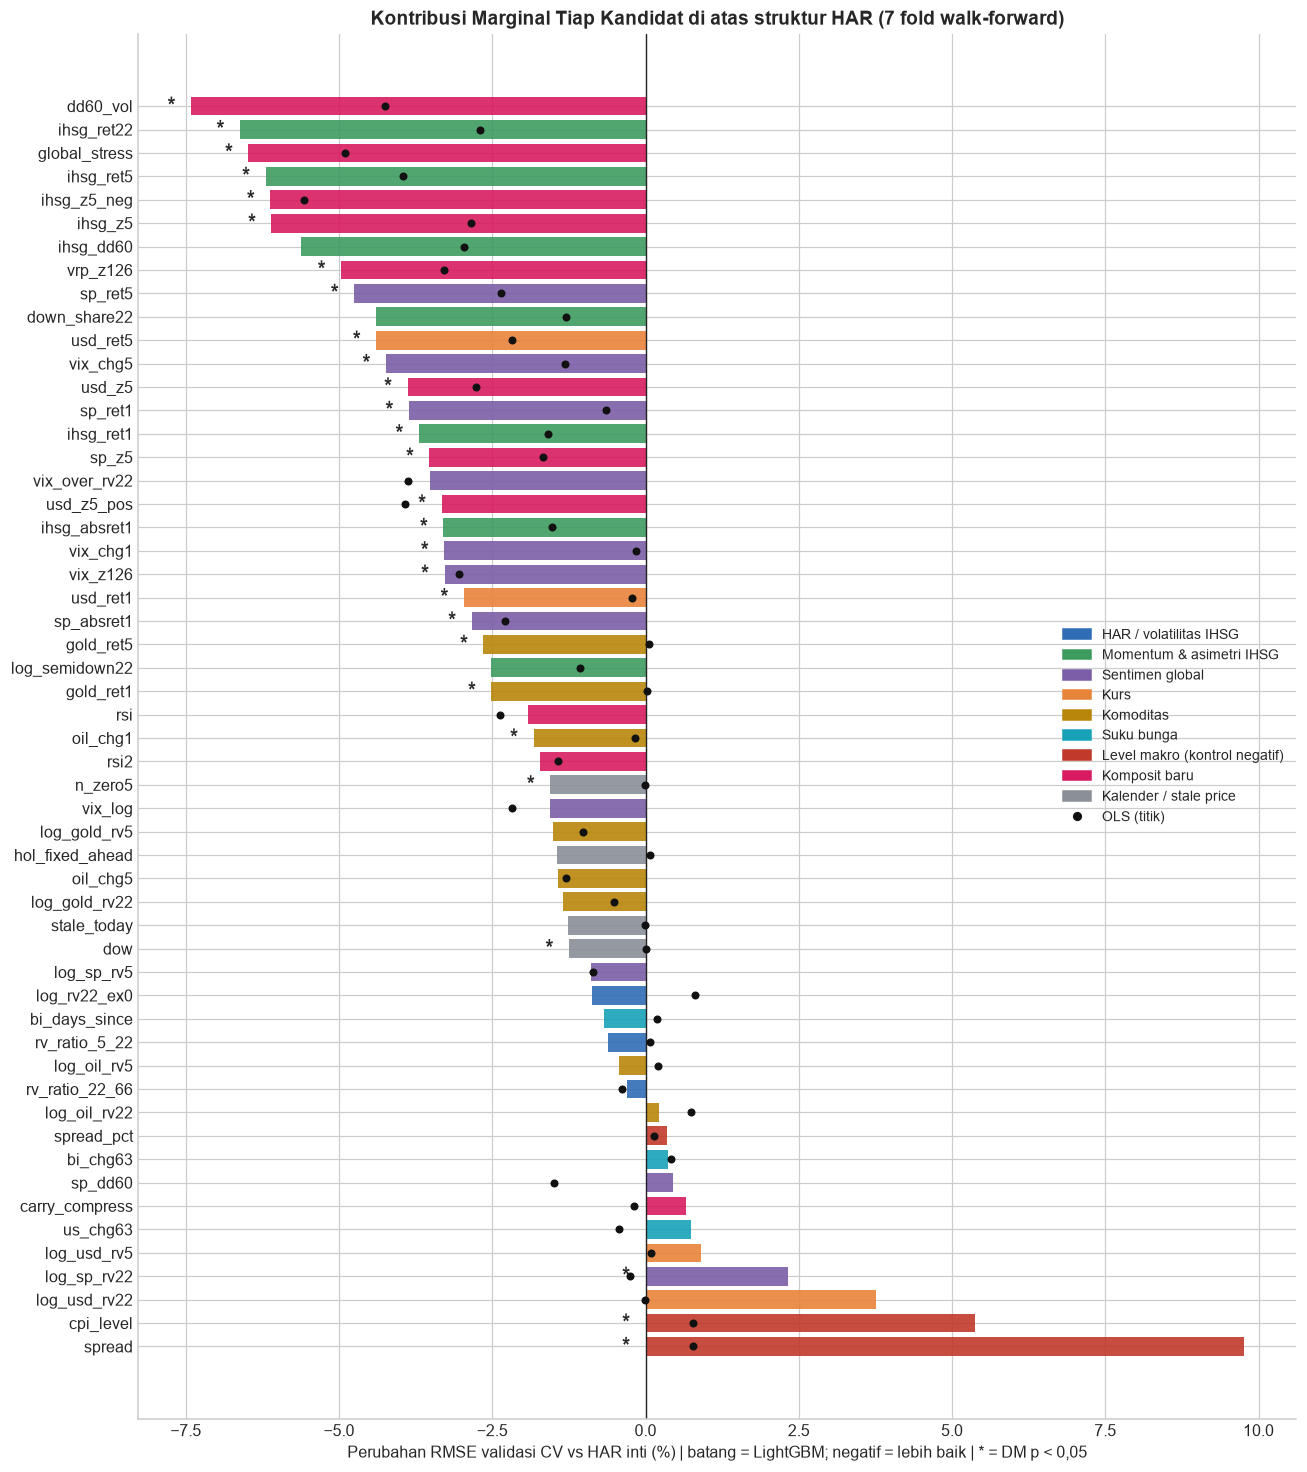

In [14]:
# 9b

SKIP = set(CORE + ["rv5", "rv22", "rv66"])
cands = [c for c in ALL_FEATS if c not in SKIP]
base_pred = {"OLS": p_har_ols, "LGBM": p_har_lgbm}
mk = {"OLS": make_ols, "LGBM": make_lgbm}

def fold_wins(pb, pn):
    return sum(metrics(yy.loc[f["val"]], pn.loc[f["val"]])["RMSE"] < metrics(yy.loc[f["val"]], pb.loc[f["val"]])["RMSE"] for f in folds)

t0 = time.time()
scr = []
for c in cands:
    row = {"fitur": c, "keluarga": FAMILY[c]}
    for n in ("OLS", "LGBM"):
        pn = run_cv(F[CORE + [c]].loc[idx], yy, folds, mk[n], "log")
        yt = yy.loc[pn.index]; mb, mn = metrics(yt, base_pred[n]), metrics(yt, pn)
        row[f"{n}_dRMSE%"] = (mn["RMSE"] / mb["RMSE"] - 1) * 100
        row[f"{n}_dQLIKE"] = mn["QLIKE"] - mb["QLIKE"]
        row[f"{n}_DM_p"]   = dm_test(yt, base_pred[n], pn, "se")[2]
        row[f"{n}_fold_membaik"] = fold_wins(base_pred[n], pn)
    scr.append(row)
scr = pd.DataFrame(scr).set_index("fitur")
print(f"Penyaringan {len(cands)} kandidat x 2 model x {len(folds)} fold selesai dalam {time.time()-t0:.0f} detik")
scr_sorted = scr.sort_values("LGBM_dRMSE%")
show_cols = ["keluarga", "OLS_dRMSE%", "OLS_DM_p", "OLS_fold_membaik", "LGBM_dRMSE%", "LGBM_DM_p", "LGBM_fold_membaik", "LGBM_dQLIKE"]
display(scr_sorted[show_cols].head(15).style.format({"OLS_dRMSE%": "{:+.2f}", "OLS_DM_p": "{:.3f}", "LGBM_dRMSE%": "{:+.2f}", "LGBM_DM_p": "{:.3f}", "LGBM_dQLIKE": "{:+.3f}"}))
print("\nKandidat yang merugikan LightGBM (dRMSE > +1%):")
display(scr_sorted[scr_sorted["LGBM_dRMSE%"] > 1][show_cols].style.format({"OLS_dRMSE%": "{:+.2f}", "OLS_DM_p": "{:.3f}", "LGBM_dRMSE%": "{:+.2f}", "LGBM_DM_p": "{:.3f}", "LGBM_dQLIKE": "{:+.3f}"}))

fam_color = {"HAR / volatilitas IHSG": BLUE, "Momentum & asimetri IHSG": GREEN, "Sentimen global": PURPLE, "Kurs": ORANGE, 
             "Komoditas": "#B8860B", "Suku bunga": "#17A2B8", "Level makro (kontrol negatif)": RED, "Komposit baru": "#D81B60",
             "Kalender / stale price": GREY}
o = scr.sort_values("LGBM_dRMSE%", ascending=False)
fig, ax = plt.subplots(figsize=(12, 13.5))
ax.barh(o.index, o["LGBM_dRMSE%"], color=[fam_color[f] for f in o["keluarga"]], alpha=0.9)
ax.scatter(o["OLS_dRMSE%"], o.index, color="#111111", s=18, zorder=4, label="OLS")
for i, (nm, r) in enumerate(o.iterrows()):
    if r["LGBM_DM_p"] < 0.05:
        ax.text(min(r["LGBM_dRMSE%"], 0) - 0.25, i, "*", ha="right", va="center", fontsize=13, fontweight="bold")
ax.axvline(0, color="#222", lw=0.9)
handles = [Rectangle((0, 0), 1, 1, color=c, label=k) for k, c in fam_color.items() if k in set(o["keluarga"])]
handles.append(plt.Line2D([], [], marker="o", color="#111", ls="", ms=5, label="OLS (titik)"))
ax.legend(handles=handles, loc="center right", fontsize=9)
ax.set_xlabel("Perubahan RMSE validasi CV vs HAR inti (%) | batang = LightGBM; negatif = lebih baik | * = DM p < 0,05")
ax.set_title("Kontribusi Marginal Tiap Kandidat di atas struktur HAR (7 fold walk-forward)")
plt.tight_layout(); save_fig(fig, "dp_5.png"); plt.show()

>INTERPRETASI (Ukuran: perubahan RMSE validasi CV terhadap HAR inti; negatif = membaik. 54 kandidat diuji.)

1. Perbaikan terbesar berasal dari asimetri dan guncangan IHSG itu sendiri, bukan dari variabel makro mentah: dd60_vol -7,4% (membaik pada 7 dari 7 fold), ihsg_ret22 -6,6%, global_stress -6,5% (DM $p=0{,}009$), ihsg_ret5 -6,2%, ihsg_z5_neg -6,1%, ihsg_z5 -6,1%. Ini mendukung *leverage effect*.
2. Fitur lintas pasar yang terstandardisasi juga kuat: vrp_z126 -5,0% (DM $p=0{,}003$), sp_ret5 -4,8%, usd_ret5 -4,4% ($p=0{,}010$), vix_chg5 -4,2% ($p<0{,}001$), usd_z5 -3,9%.
3. Kontrol negatif terbukti merugikan, sesuai dugaan. spread (level selisih bunga) +9,8% (hanya membaik pada 2 dari 7 fold), cpi_level +5,4% ($p=0{,}018$), log_usd_rv22 +3,8%, log_sp_rv22 +2,3%. Fitur level dan fitur yang melacak rezim membuat model menghafal periode, bukan mempelajari mekanisme. Pada OLS dampaknya jauh lebih kecil (di bawah +1%), yang konsisten dengan penjelasan bahwa model pohon-lah yang paling rentan menghafal rezim.
4. Pembalikan terhadap temuan Tahap 2. Perubahan VIX 5 hari hanya berkorelasi 0,11 pada analisis univariat, tetapi di atas HAR ia menurunkan RMSE LightGBM 4,2% ($p<0{,}001$). Korelasi univariat dapat menyesatkan. Kontribusi marginal adalah ukuran yang tepat.
5. Dengan 54 kandidat, beberapa $p$-value kecil dapat muncul secara kebetulan. Karena itu *p-value* di sini dipakai sebagai alat pemeringkatan, dan klaim yang tidak bias hanya diambil dari blok *holdout*.

#### ****9C. Skor Hipotesis: Apa yang Terdukung dan Apa yang Tidak****

Register hipotesis (Tahap 1, Business Understanding) dibuka kembali. Setiap hipotesis dinilai dari fitur-fitur yang mewakilinya. Aturan putusan (ditetapkan sebelum melihat hasil akhir): *terdukung* bila LightGBM membaik >= 1,5% dengan DM $p<0{,}10$; *terdukung sebagian* bila membaik >= 0,5% pada salah satu model; selain itu *tidak terdukung*. Hipotesis yang gagal dilaporkan apa adanya. Pada beberapa kasus kami memodifikasinya dan menguji ulang (dicatat eksplisit sebagai versi baru).

In [15]:
# 9c

H_MAP = {
 "H1 (naif): VRP proxy = VIX terskala - RV": ["vix_over_rv22"],
 "H1 (revisi): Fear Gap ter-standarisasi": ["vrp_z126"],
 "H2 (awal): RSI = z kurs x (1 - persentil spread)": ["rsi"],
 "H2 (kurs saja): guncangan depresiasi rupiah": ["usd_z5", "usd_ret5"],
 "H2 (carry): penyempitan selisih bunga": ["carry_compress", "rsi2"],
 "H3: rasio RV5/RV22 (mean reversion)": ["rv_ratio_5_22", "rv_ratio_22_66"],
 "H4: asimetri / leverage effect": ["down_share22", "log_semidown22", "ihsg_dd60", "ihsg_z5_neg", "dd60_vol"],
 "H5: guncangan emas dan minyak": ["gold_ret5", "log_gold_rv5", "oil_chg5", "log_oil_rv5"],
 "H6: percepatan dan level ketakutan global": ["vix_chg5", "vix_z126", "sp_z5", "sp_ret5"],
 "H7: hari sejak perubahan suku bunga BI": ["bi_days_since", "bi_chg63"],
}
def verdict(feats):
    s = scr.loc[feats]
    best = s["LGBM_dRMSE%"].idxmin()
    rl, rp = s.loc[best, "LGBM_dRMSE%"], s.loc[best, "LGBM_DM_p"]
    ro = s["OLS_dRMSE%"].min()
    if rl <= -1.5 and rp < 0.10: v = "TERDUKUNG"
    elif rl <= -0.5 or ro <= -0.5: v = "terdukung sebagian"
    else: v = "TIDAK terdukung"
    return pd.Series({"fitur_terbaik": best, "LGBM_dRMSE%": rl, "LGBM_DM_p": rp, "OLS_dRMSE_terbaik%": ro, "putusan": v})
hv = pd.DataFrame({k: verdict(v) for k, v in H_MAP.items()}).T
display(hv.style.format({"LGBM_dRMSE%": "{:+.2f}", "LGBM_DM_p": "{:.3f}", "OLS_dRMSE_terbaik%": "{:+.2f}"}))
hv.to_csv(NOTE_DIR / "hypothesis_verdict.csv")

,fitur_terbaik,LGBM_dRMSE%,LGBM_DM_p,OLS_dRMSE_terbaik%,putusan
H1 (naif): VRP proxy = VIX terskala - RV,vix_over_rv22,-3.51,0.123,-3.87,terdukung sebagian
H1 (revisi): Fear Gap ter-standarisasi,vrp_z126,-4.97,0.003,-3.29,TERDUKUNG
H2 (awal): RSI = z kurs x (1 - persentil spread),rsi,-1.92,0.138,-2.37,terdukung sebagian
H2 (kurs saja): guncangan depresiasi rupiah,usd_ret5,-4.39,0.010,-2.77,TERDUKUNG
H2 (carry): penyempitan selisih bunga,rsi2,-1.72,0.247,-1.43,terdukung sebagian
H3: rasio RV5/RV22 (mean reversion),rv_ratio_5_22,-0.61,0.231,-0.39,terdukung sebagian
H4: asimetri / leverage effect,dd60_vol,-7.42,0.038,-5.58,TERDUKUNG
H5: guncangan emas dan minyak,gold_ret5,-2.64,0.026,-1.30,TERDUKUNG
H6: percepatan dan level ketakutan global,sp_ret5,-4.75,0.025,-3.05,TERDUKUNG
H7: hari sejak perubahan suku bunga BI,bi_days_since,-0.68,0.579,+0.19,terdukung sebagian


>INTERPRETASI Putusan otomatis menurut aturan yang ditetapkan sebelumnya, ditambah pembacaan kami.

| Hipotesis | Putusan | Bacaan |
|---|---|---|
| H1 (naif) VRP = VIX - RV | sebagian ($-3{,}5\%$, $p=0{,}12$) | Bentuk mentah memberi sinyal tetapi tidak meyakinkan |
| H1 (revisi) Fear Gap ter-standarisasi | terdukung ($-5{,}0\%$, $p=0{,}003$) | Hipotesis awal diperbaiki: standardisasi 126 hari membuatnya sebanding antar rezim |
| H2 (awal) RSI = z kurs × (1 - persentil spread) | sebagian ($-1{,}9\%$, $p=0{,}14$) | Komponen suku bunga melemahkan fitur |
| H2 (kurs saja) guncangan depresiasi rupiah | terdukung (usd_ret5 $-4{,}4\%$, $p=0{,}010$) | Saluran kurs nyata, tanpa suku bunga |
| H2 (carry) penyempitan selisih bunga | tidak mendukung (carry_compress sendirian +0,7%; rsi2 −1,7%, $p=0{,}25$) | Bagian suku bunga dari hipotesis kami ditolak |
| H3 rasio RV5/RV22 | lemah ($-0{,}6\%$, $p=0{,}23$) | Secara efektif tidak terdukung; informasinya sudah ada pada HAR |
| H4 asimetri/*leverage effect* | terdukung (dd60_vol $-7{,}4\%$, $p=0{,}038$) | Hipotesis terkuat |
| H5 emas dan minyak | terdukung sebagian (emas gold_ret5 $-2{,}6\%$, $p=0{,}026$; minyak lemah) | Emas berfungsi sebagai sinyal *safe haven*; minyak tidak |
| H6 ketakutan global | terdukung (sp_ret5 $-4{,}8\%$; vix_chg5 $-4{,}2\%$) | Guncangan S&P 500 dan percepatan VIX berpengaruh |
| H7 hari sejak perubahan BI_rate | tidak meyakinkan ($-0{,}7\%$, $p=0{,}58$) | Secara efektif tidak terdukung; ketepatan waktu data BI_rate berbeda sebelum dan sesudah 2016 (Notebook 2) |

Aturan otomatis bersifat longgar untuk label "sebagian" (cukup >= 0,5%), sehingga H3 dan H7 sebenarnya lemah ($p>0{,}2$) dan kami tidak akan mengklaimnya. Empat dari tujuh hipotesis terdukung (H1 revisi, H2 saluran kurs, H4, H6), satu sebagian (H5), dan dua tidak terdukung (H3, H7); bagian suku bunga dari H2 juga ditolak. Menyatakan hipotesis yang ditolak adalah bagian dari nilai ilmiah analisis, dan juga menjawab permintaan EDA & logika pada rubrik.

#### ****9D. Forward Selection Sebagai Pemeriksaan Independen****

Penyaringan satu per satu tidak menangkap tumpang tindih antar fitur. Sebagai pemeriksaan independen, kami menjalankan forward selection serakah pada LightGBM dimana mulai dari inti HAR, tambahkan fitur yang paling menurunkan RMSE CV, ulangi sampai perbaikan berikutnya kurang dari 0,3%. Kandidatnya adalah fitur yang tidak merugikan pada penyaringan (fitur level dan yang merugikan dikeluarkan). Bila fitur yang dipilih algoritma ini sejalan dengan analisis ekonomi pada 9C, maka dimiliki dua jalur independen yang menunjuk ke arah yang sama.

In [16]:
# 9d

pool = [c for c in cands if scr.loc[c, "LGBM_dRMSE%"] < 0 or scr.loc[c, "OLS_dRMSE%"] < 0]
pool = [c for c in pool if FAMILY[c] != "Level makro (kontrol negatif)"]
print(f"Kandidat tidak merugikan yang masuk seleksi maju: {len(pool)} dari {len(cands)}")

sel, steps = [], []
cur_p = p_har_lgbm; cur_r = pooled(cur_p)["RMSE"]; t0 = time.time()
for step in range(1, 9):
    best = None
    for c in pool:
        if c in sel: continue
        p = run_cv(F[CORE + sel + [c]].loc[idx], yy, folds, make_lgbm, "log"); r = pooled(p)["RMSE"]
        if best is None or r < best[1]: best = (c, r)
    gain = (best[1] / cur_r - 1) * 100
    steps.append({"langkah": step, "fitur_ditambahkan": best[0], "keluarga": FAMILY[best[0]], "RMSE_CV": best[1], "perbaikan_%": gain})
    if gain > -0.3:
        steps[-1]["keputusan"] = "berhenti (perbaikan < 0,3%)"; break
    steps[-1]["keputusan"] = "diterima"; sel.append(best[0]); cur_r = best[1]
fs_tbl = pd.DataFrame(steps)
display(fs_tbl.style.format({"RMSE_CV": "{:.5f}", "perbaikan_%": "{:+.2f}"}).hide(axis="index"))
print(f"Terpilih (seleksi maju): {sel} | waktu {time.time()-t0:.0f} detik")
FWD_SELECTED = sel

Kandidat tidak merugikan yang masuk seleksi maju: 48 dari 54


langkah,fitur_ditambahkan,keluarga,RMSE_CV,perbaikan_%,keputusan
1,dd60_vol,Komposit baru,0.00450,-7.42,diterima
2,vrp_z126,Komposit baru,0.00433,-3.88,diterima
3,ihsg_ret22,Momentum & asimetri IHSG,0.00421,-2.70,diterima
4,usd_z5,Komposit baru,0.00414,-1.62,diterima
5,n_zero5,Kalender / stale price,0.00414,+0.02,"berhenti (perbaikan < 0,3%)"


Terpilih (seleksi maju): ['dd60_vol', 'vrp_z126', 'ihsg_ret22', 'usd_z5'] | waktu 122 detik


>INTERPRETASI

1. forward selection memilih empat fitur lalu berhenti, urutannya: dd60_vol (-7,4%; RMSE CV 0,00450), vrp_z126 (-3,9%; 0,00433), ihsg_ret22 (-2,7%; 0,00421), dan usd_z5 (-1,6%; 0,00414). Langkah kelima (n_zero5) hanya memperbaiki 0,02%, sehingga algoritma berhenti.
2. Tiga dari empat fitur yang dipilih algoritma adalah X3, X1, dan X2 kami, dan urutan pemilihannya (X3 dahulu, lalu X1, lalu X2) sama dengan peringkat kontribusi marginalnya. Ini pemeriksaan independen dmn kami tidak memilih fitur-fitur itu lebih dulu lalu mencari pembenaran; algoritma yang tidak mengetahui narasi ekonomi sampai ke kesimpulan yang sama.
3. Total perbaikan dari HAR inti LightGBM (0,00486) ke empat fitur (0,00414) adalah -14,8%. Pool kandidat (48 dari 54) sudah membuang fitur yang terbukti merugikan.
4. ihsg_ret22 ikut dibawa ke set S3 (diperluas), tetapi tidak menjadi bagian X1-X3 karena bukan fitur turunan baru (hanya *return* kumulatif 22 hari).

#### ****9E. Pemilihan X1–X3****

Kriteria pemilihan (ditetapkan eksplisit agar dapat diaudit):
1. Tiga saluran ekonomi yang berbeda (sentimen global, kurs, asimetri domestik), agar ketiganya tidak sekadar menyalin satu sama lain.
2. Kontribusi marginal terbaik pada gabungan, di kedua model, dengan perbaikan pada mayoritas fold.
3. Selaras dengan seleksi maju pada 9D (pemeriksaan independen).
4. Berwujud fitur turunan baru, bukan variabel mentah: seluruhnya adalah *standardized shock*.

Tabel di bawah membandingkan beberapa paket kandidat.

In [17]:
# 9e

bundles = {
 "A: vrp_z126 + usd_z5 + dd60_vol": ["vrp_z126", "usd_z5", "dd60_vol"],
 "B: vrp_z126 + global_stress + dd60_vol": ["vrp_z126", "global_stress", "dd60_vol"],
 "C: vrp_z126 + usd_z5 + ihsg_z5_neg": ["vrp_z126", "usd_z5", "ihsg_z5_neg"],
 "D: global_stress + vrp_z126 + ihsg_z5_neg": ["global_stress", "vrp_z126", "ihsg_z5_neg"],
 "E: vix_z126 + usd_z5 + ihsg_dd60 (tanpa komposit baru)": ["vix_z126", "usd_z5", "ihsg_dd60"],
 "F: vix_over_rv22 + rsi + down_share22 (hipotesis awal)": ["vix_over_rv22", "rsi", "down_share22"],
}
rows = []
for name, fs in bundles.items():
    row = {"paket": name}
    for n in ("OLS", "LGBM"):
        pn = run_cv(F[CORE + fs].loc[idx], yy, folds, mk[n], "log"); yt = yy.loc[pn.index]
        mb, mn = metrics(yt, base_pred[n]), metrics(yt, pn)
        row[f"{n}_dRMSE%"] = (mn["RMSE"] / mb["RMSE"] - 1) * 100
        row[f"{n}_dQLIKE"] = mn["QLIKE"] - mb["QLIKE"]
        row[f"{n}_DM_p"] = dm_test(yt, base_pred[n], pn, "se")[2]
        row[f"{n}_fold_membaik"] = fold_wins(base_pred[n], pn)
    rows.append(row)
bund_tbl = pd.DataFrame(rows).set_index("paket")
display(bund_tbl.style.format({"OLS_dRMSE%": "{:+.2f}", "OLS_dQLIKE": "{:+.3f}", "OLS_DM_p": "{:.3f}", "LGBM_dRMSE%": "{:+.2f}", "LGBM_dQLIKE": "{:+.3f}", "LGBM_DM_p": "{:.3f}"}))

X1, X2, X3 = "vrp_z126", "usd_z5", "dd60_vol"
X_NAMES = {X1: "X1 Fear Gap", X2: "X2 Rupiah Shock", X3: "X3 Drawdown-Vol"}
CORE_X = CORE + [X1, X2, X3]

full_p = {n: run_cv(F[CORE_X].loc[idx], yy, folds, mk[n], "log") for n in ("OLS", "LGBM")}
abl = []
for f_ in [X1, X2, X3]:
    keep = [c for c in CORE_X if c != f_]
    row = {"fitur_dilepas": X_NAMES[f_]}
    for n in ("OLS", "LGBM"):
        pn = run_cv(F[keep].loc[idx], yy, folds, mk[n], "log"); yt = yy.loc[pn.index]
        row[f"{n}_RMSE_naik_%"] = (metrics(yt, pn)["RMSE"] / metrics(yt, full_p[n])["RMSE"] - 1) * 100
        row[f"{n}_DM_p"] = dm_test(yt, pn, full_p[n], "se")[2]
    abl.append(row)
display(pd.DataFrame(abl).set_index("fitur_dilepas").style.format({"OLS_RMSE_naik_%": "{:+.2f}", "LGBM_RMSE_naik_%": "{:+.2f}", "OLS_DM_p": "{:.3f}", "LGBM_DM_p": "{:.3f}"})
        .set_caption("Ablasi: kenaikan RMSE bila satu fitur X dilepas dari model lengkap (positif = fitur berguna)"))
print("Seleksi maju memilih:", FWD_SELECTED, "| Irisan dengan X1-X3:", sorted(set(FWD_SELECTED) & {X1, X2, X3}))

two = CORE + [X1, X3]
base2 = {n: run_cv(F[two].loc[idx], yy, folds, mk[n], "log") for n in ("OLS", "LGBM")}
slot = []
for c in ["usd_z5", "usd_ret5", "usd_z5_pos", "global_stress", "sp_z5", "sp_ret5", "vix_chg5", "ihsg_ret22", "ihsg_z5_neg", "gold_ret5", "ihsg_ret1", "sp_ret1"]:
    r_ = {"kandidat_pelengkap": c, "keluarga": FAMILY[c]}
    for n in ("OLS", "LGBM"):
        pn = run_cv(F[two + [c]].loc[idx], yy, folds, mk[n], "log"); yt = yy.loc[pn.index]
        mb, mn = metrics(yt, base2[n]), metrics(yt, pn)
        r_[f"{n}_dRMSE%"] = (mn["RMSE"] / mb["RMSE"] - 1) * 100
        r_[f"{n}_DM_p"] = dm_test(yt, base2[n], pn, "se")[2]
    slot.append(r_)
slot = pd.DataFrame(slot).set_index("kandidat_pelengkap").sort_values("LGBM_dRMSE%")
display(slot.style.format({"OLS_dRMSE%": "{:+.2f}", "OLS_DM_p": "{:.3f}", "LGBM_dRMSE%": "{:+.2f}", "LGBM_DM_p": "{:.3f}"})
        .set_caption("Kandidat pelengkap di atas HAR + X1 + X3 (negatif = membaik)"))

,OLS_dRMSE%,OLS_dQLIKE,OLS_DM_p,OLS_fold_membaik,LGBM_dRMSE%,LGBM_dQLIKE,LGBM_DM_p,LGBM_fold_membaik
paket,,,,,,,,
A: vrp_z126 + usd_z5 + dd60_vol,-9.61,-0.069,0.059,6,-12.49,-0.081,0.035,6
B: vrp_z126 + global_stress + dd60_vol,-8.28,-0.070,0.042,5,-11.14,-0.073,0.029,6
C: vrp_z126 + usd_z5 + ihsg_z5_neg,-9.30,-0.071,0.068,6,-9.14,-0.075,0.013,6
D: global_stress + vrp_z126 + ihsg_z5_neg,-8.32,-0.072,0.050,7,-8.40,-0.070,0.006,6
E: vix_z126 + usd_z5 + ihsg_dd60 (tanpa komposit baru),-7.00,-0.065,0.116,6,-7.88,-0.061,0.041,5
F: vix_over_rv22 + rsi + down_share22 (hipotesis awal),-7.01,-0.069,0.130,3,-5.38,-0.048,0.352,3


,OLS_RMSE_naik_%,OLS_DM_p,LGBM_RMSE_naik_%,LGBM_DM_p
fitur_dilepas,,,,
X1 Fear Gap,+4.01,0.060,+6.18,0.067
X2 Rupiah Shock,+1.66,0.138,+0.67,0.269
X3 Drawdown-Vol,+4.11,0.061,+5.29,0.105


Seleksi maju memilih: ['dd60_vol', 'vrp_z126', 'ihsg_ret22', 'usd_z5'] | Irisan dengan X1-X3: ['dd60_vol', 'usd_z5', 'vrp_z126']


,keluarga,OLS_dRMSE%,OLS_DM_p,LGBM_dRMSE%,LGBM_DM_p
kandidat_pelengkap,,,,,
usd_ret5,Kurs,-1.31,0.102,-1.58,0.007
ihsg_ret22,Momentum & asimetri IHSG,-0.01,0.857,-1.48,0.226
usd_z5,Komposit baru,-1.63,0.138,-0.77,0.285
usd_z5_pos,Komposit baru,-2.47,0.151,+0.09,0.870
global_stress,Komposit baru,-0.18,0.693,+0.25,0.873
ihsg_z5_neg,Komposit baru,-1.93,0.146,+0.34,0.801
ihsg_ret1,Momentum & asimetri IHSG,-0.29,0.397,+0.72,0.383
sp_ret5,Sentimen global,-0.04,0.943,+1.24,0.410
sp_z5,Komposit baru,+0.71,0.334,+1.90,0.320


>INTERPRETASI

1. Paket A menang pada kedua model: RMSE turun 9,6% (OLS) dan 12,5% (LightGBM) terhadap HAR inti, QLIKE turun 0,069 dan 0,081, membaik pada 6 dari 7 fold, dengan DM $p=0{,}059$ (OLS) dan $p=0{,}035$ (LightGBM).
2. Komposit baru mengungguli versi sederhananya. Paket E (variabel yang tidak dibakukan: vix_z126, usd_z5, ihsg_dd60) hanya -7,0% / -7,9%; paket F, yang memakai hipotesis awal kami (vix_over_rv22, rsi, down_share22), paling lemah: -7,0% / -5,4%, dan hanya membaik pada 3 dari 7 fold. Jadi revisi hipotesis memang meningkatkan kualitas fitur.
3. Ablasi menunjukkan kontribusi yang tidak merata, dan kami melaporkannya jujur. Bila dilepas dari model lengkap, RMSE naik +4,0% (OLS) / +6,2% (LightGBM) tanpa X1, +4,1% / +5,3% tanpa X3, tetapi hanya +1,7% / +0,7% tanpa X2 ($p=0{,}14$ dan $0{,}27$). Jadi X1 dan X3 adalah penggerak utama, sedangkan X2 adalah kontributor terkecil setelah dua lainnya hadir. Karena nilai $p$ individual berada di kisaran 0,06-0,14, atribusi per fitur kurang presisi meskipun paket gabungannya signifikan.
4. Pemeriksaan slot X2. Setelah HAR + X1 + X3, kandidat pelengkap terbaik adalah saluran kurs: usd_ret5 -1,6% (LightGBM, $p=0{,}007$) dan usd_z5 -0,8% / -1,6% (LightGBM / OLS). Kandidat lain (S&P 500, VIX, emas, *return* IHSG, global_stress) tidak menambah apa pun atau malah merugikan (hingga +2,2%). Artinya, sinyal tersisa setelah X1 dan X3 sedikit, dan kurs adalah yang terbaik di antaranya.
5. Keputusan: X1 = vrp_z126, X2 = usd_z5, X3 = dd60_vol. X2 dipertahankan karena (a) ia mewakili saluran ekonomi yang berbeda dan eksplisit dalam studi kasus (kurs), (b) signifikan secara individual (Bagian 9B dan 10), (c) tanda hubungannya stabil 93% waktu, dan (d) dipilih seleksi maju pada langkah keempat. Klaim kami atasnya dibatasi pada kontribusi ≈ 1%.

### ****10. Uji Validitas Kuantitatf X1 - X3 (Task 1)****

Studi kasus meminta visualisasi yang membuktikan secara kuantitatif bahwa tiga fitur terpilih berkorelasi atau berkontribusi signifikan terhadap $Y$. Kami menyajikan lima bukti yang saling melengkapi, masing-masing menutup kelemahan bukti lainnya:

| # | Bukti | Pertanyaan yang dijawab |
|---|---|---|
| 1 | Heatmap korelasi Spearman | Apakah ada hubungan, dan apakah X1 - X3 tidak saling menyalin? |
| 2 | Korelasi parsial (kontrol HAR) | Apakah hubungannya masih ada setelah volatilitas IHSG dikendalikan? |
| 3 | Profil kuintil | Apakah hubungannya monoton dan bermakna secara bisnis? |
| 4 | Stabilitas korelasi bergulir | Apakah hubungan itu stabil antar waktu, atau hanya kebetulan pada satu periode? |
| 5 | Kontribusi per fold dan *holdout* | Apakah penambahan X membantu secara konsisten di luar sampel? |

Inferensi memakai sampel efektif (setiap baris ke-5) karena labelnya itu tumpang tindih.

,rho_Spearman,rho_sub5,p_sub5,rho_parsial (kontrol HAR),rho_parsial_sub5,p_parsial_sub5,n_efektif
fitur,,,,,,,
X1 Fear Gap,-0.082,-0.097,1.3e-02,+0.114,+0.106,6.2e-03,661
X2 Rupiah Shock,+0.109,+0.114,3.3e-03,+0.109,+0.101,9.1e-03,661
X3 Drawdown-Vol,-0.252,-0.252,5.4e-11,-0.157,-0.151,9.9e-05,661


Gambar disimpan: xLain-Lain/img/dp_6.png


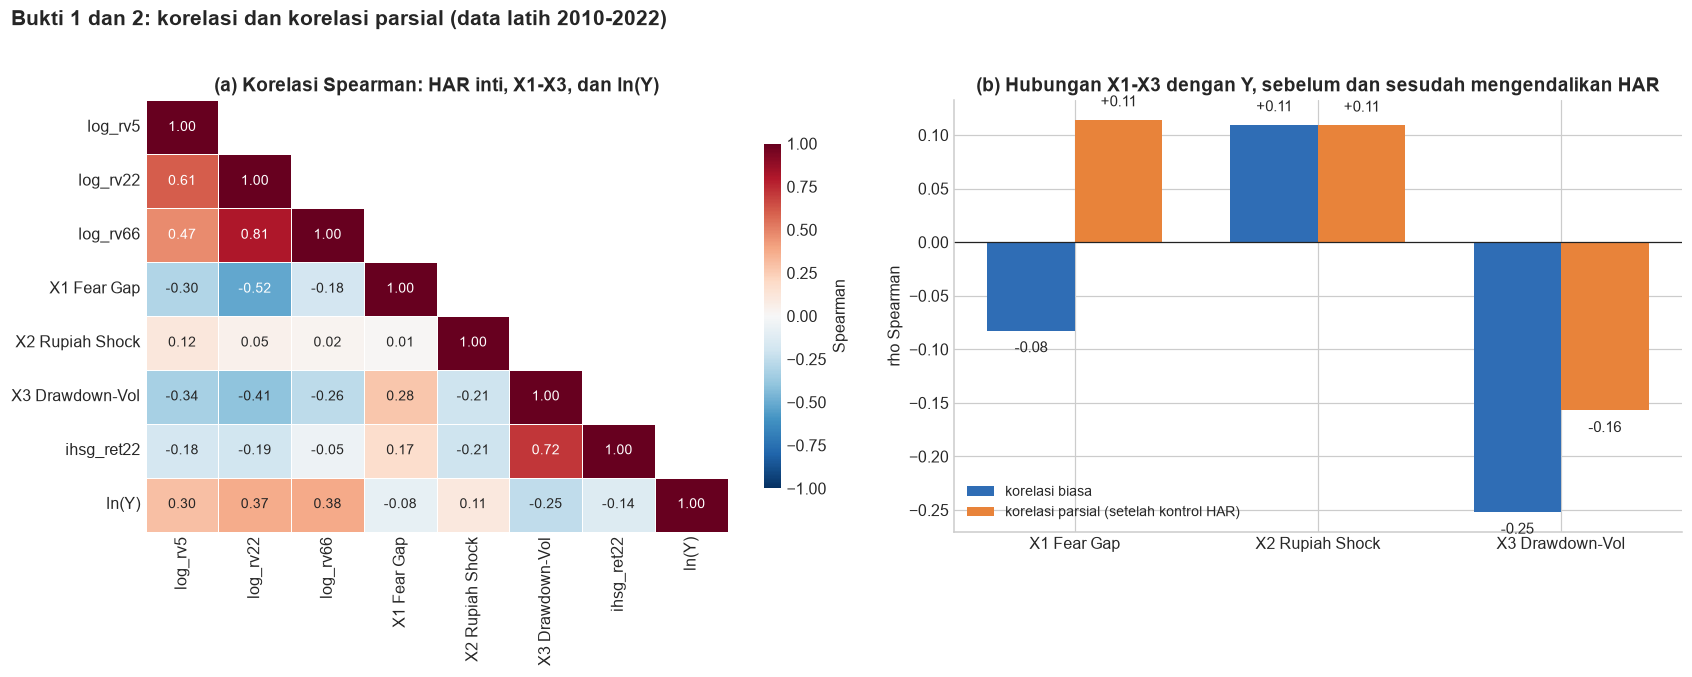

In [18]:
# 10A bukti 1 - 2

LATIH = idx[idx <= "2022-12-31"]
Z = pd.concat([F.loc[LATIH, CORE + [X1, X2, X3, "ihsg_ret22"]], np.log(yy.loc[LATIH] + EPS_T).rename("ln(Y)")], axis=1)

# spearman terhadap Y (skala asli) dan inferensi pada sub-sampel tak tumpang tindih
rows = []
for c in [X1, X2, X3]:
    a_full = stats.spearmanr(F.loc[LATIH, c], yy.loc[LATIH])
    sub = LATIH[::5]
    a_sub = stats.spearmanr(F.loc[sub, c], yy.loc[sub])
    # residualkan ln(Y) dan X terhadap inti HAR
    Xc = sm.add_constant(F.loc[LATIH, CORE])
    ry = sm.OLS(np.log(yy.loc[LATIH] + EPS_T), Xc).fit().resid
    rx = sm.OLS(F.loc[LATIH, c], Xc).fit().resid
    pr_full = stats.spearmanr(rx, ry)
    pr_sub = stats.spearmanr(rx.loc[sub], ry.loc[sub])
    rows.append({"fitur": X_NAMES[c], "rho_Spearman": a_full[0], "rho_sub5": a_sub[0], "p_sub5": a_sub[1],
                 "rho_parsial (kontrol HAR)": pr_full[0], "rho_parsial_sub5": pr_sub[0], "p_parsial_sub5": pr_sub[1], "n_efektif": len(sub)})
val_tbl = pd.DataFrame(rows).set_index("fitur")
display(val_tbl.style.format({"rho_Spearman": "{:+.3f}", "rho_sub5": "{:+.3f}", "p_sub5": "{:.1e}", "rho_parsial (kontrol HAR)": "{:+.3f}",
                              "rho_parsial_sub5": "{:+.3f}", "p_parsial_sub5": "{:.1e}"}))

fig, axes = plt.subplots(1, 2, figsize=(15.5, 6))
cm = Z.rename(columns={X1: "X1 Fear Gap", X2: "X2 Rupiah Shock", X3: "X3 Drawdown-Vol"}).corr(method="spearman")
sns.heatmap(cm, mask=np.triu(np.ones_like(cm, dtype=bool), k=1), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.4, cbar_kws={"shrink": 0.8, "label": "Spearman"}, ax=axes[0], annot_kws={"fontsize": 9})
axes[0].set_title("(a) Korelasi Spearman: HAR inti, X1-X3, dan ln(Y)"); axes[0].grid(False)
ax = axes[1]
vt = val_tbl.reset_index()
xp = np.arange(len(vt)); w = 0.36
ax.bar(xp - w/2, vt["rho_Spearman"], w, color=BLUE, label="korelasi biasa")
ax.bar(xp + w/2, vt["rho_parsial (kontrol HAR)"], w, color=ORANGE, label="korelasi parsial (setelah kontrol HAR)")
for i, r in vt.iterrows():
    ax.text(i - w/2, r["rho_Spearman"] + 0.01 * np.sign(r["rho_Spearman"]), f"{r['rho_Spearman']:+.2f}", ha="center", va="bottom" if r["rho_Spearman"] > 0 else "top", fontsize=9.5)
    ax.text(i + w/2, r["rho_parsial (kontrol HAR)"] + 0.01 * np.sign(r["rho_parsial (kontrol HAR)"]), f"{r['rho_parsial (kontrol HAR)']:+.2f}",
            ha="center", va="bottom" if r["rho_parsial (kontrol HAR)"] > 0 else "top", fontsize=9.5)
ax.axhline(0, color="#222", lw=0.8); ax.set_xticks(xp); ax.set_xticklabels(vt["fitur"]); ax.set_ylabel("rho Spearman")
ax.set_title("(b) Hubungan X1-X3 dengan Y, sebelum dan sesudah mengendalikan HAR"); ax.legend(loc="best", fontsize=9)
fig.suptitle("Bukti 1 dan 2: korelasi dan korelasi parsial (data latih 2010-2022)", x=0.01, ha="left", fontweight="bold", fontsize=13.5, y=1.02)
plt.tight_layout(); save_fig(fig, "dp_6.png"); plt.show()

>INTERPRETASI (Sampel efektif $n=661$ baris; inferensi pada setiap baris ke-5.)

1. X3 *Drawdown-Vol*: hubungan terkuat dan paling bersih. Korelasi biasa -0,25 ($p=5\times10^{-11}$), tetap -0,16 setelah HAR dikendalikan ($p<10^{-4}$). Tandanya sesuai teori dimana semakin dalam penurunan IHSG dari puncaknya (nilai makin negatif), semakin tinggi volatilitas ke depan.

2. X2 *Rupiah Shock*: korelasi biasa +0,11 ($p=0{,}003$) dan korelasi parsial +0,11 ($p=0{,}009$), hampir tidak berubah setelah kontrol HAR. Ini menunjukkan sinyal kurs hampir tidak tumpang tindih dengan volatilitas IHSG masa lalu.

3. X1 *Fear Gap* membalik tanda, dan ini perlu dijelaskan. Korelasi biasa negatif (−-0,08; $p=0{,}013$), tetapi korelasi parsial positif (+0,11; $p=0{,}006$). Ini bukan kontradiksi, dan peta panas (Gambar a) memberi buktinya: X1 berkorelasi -0,52 dengan log_rv22. Secara matematis $X_1 = z\big(\ln VIX_{harian} - \ln RV_{22}\big)$ menurun terhadap $RV_{22}$, sedangkan $RV_{22}$ adalah penentu terkuat $Y$. Akibatnya, tanpa kontrol, X1 tampak berkorelasi negatif karena "meminjam" tanda $RV_{22}$ (*efek penekanan*). Setelah volatilitas masa lalu dikendalikan, yang tersisa adalah informasi inti H1: ketika ketakutan global lebih besar daripada gejolak lokal yang sudah terjadi, volatilitas IHSG cenderung menyusul naik. Konsekuensinya, X1 hanya bermakna di dalam model yang memuat HAR; korelasi biasa saja menyesatkan.
4. Ketiga fitur bukan salinan satu sama lain: korelasi antar X1-X3 rendah (0,01 sampai 0,28 secara mutlak), sehingga masing-masing membawa informasi tambahan. Satu catatan: ihsg_ret22 berkorelasi 0,72 dengan X3, yang menjelaskan mengapa fitur itu hanya menjadi tambahan ketiga pada seleksi maju dan tidak dijadikan salah satu X.

Gambar disimpan: xLain-Lain/img/dp_7.png


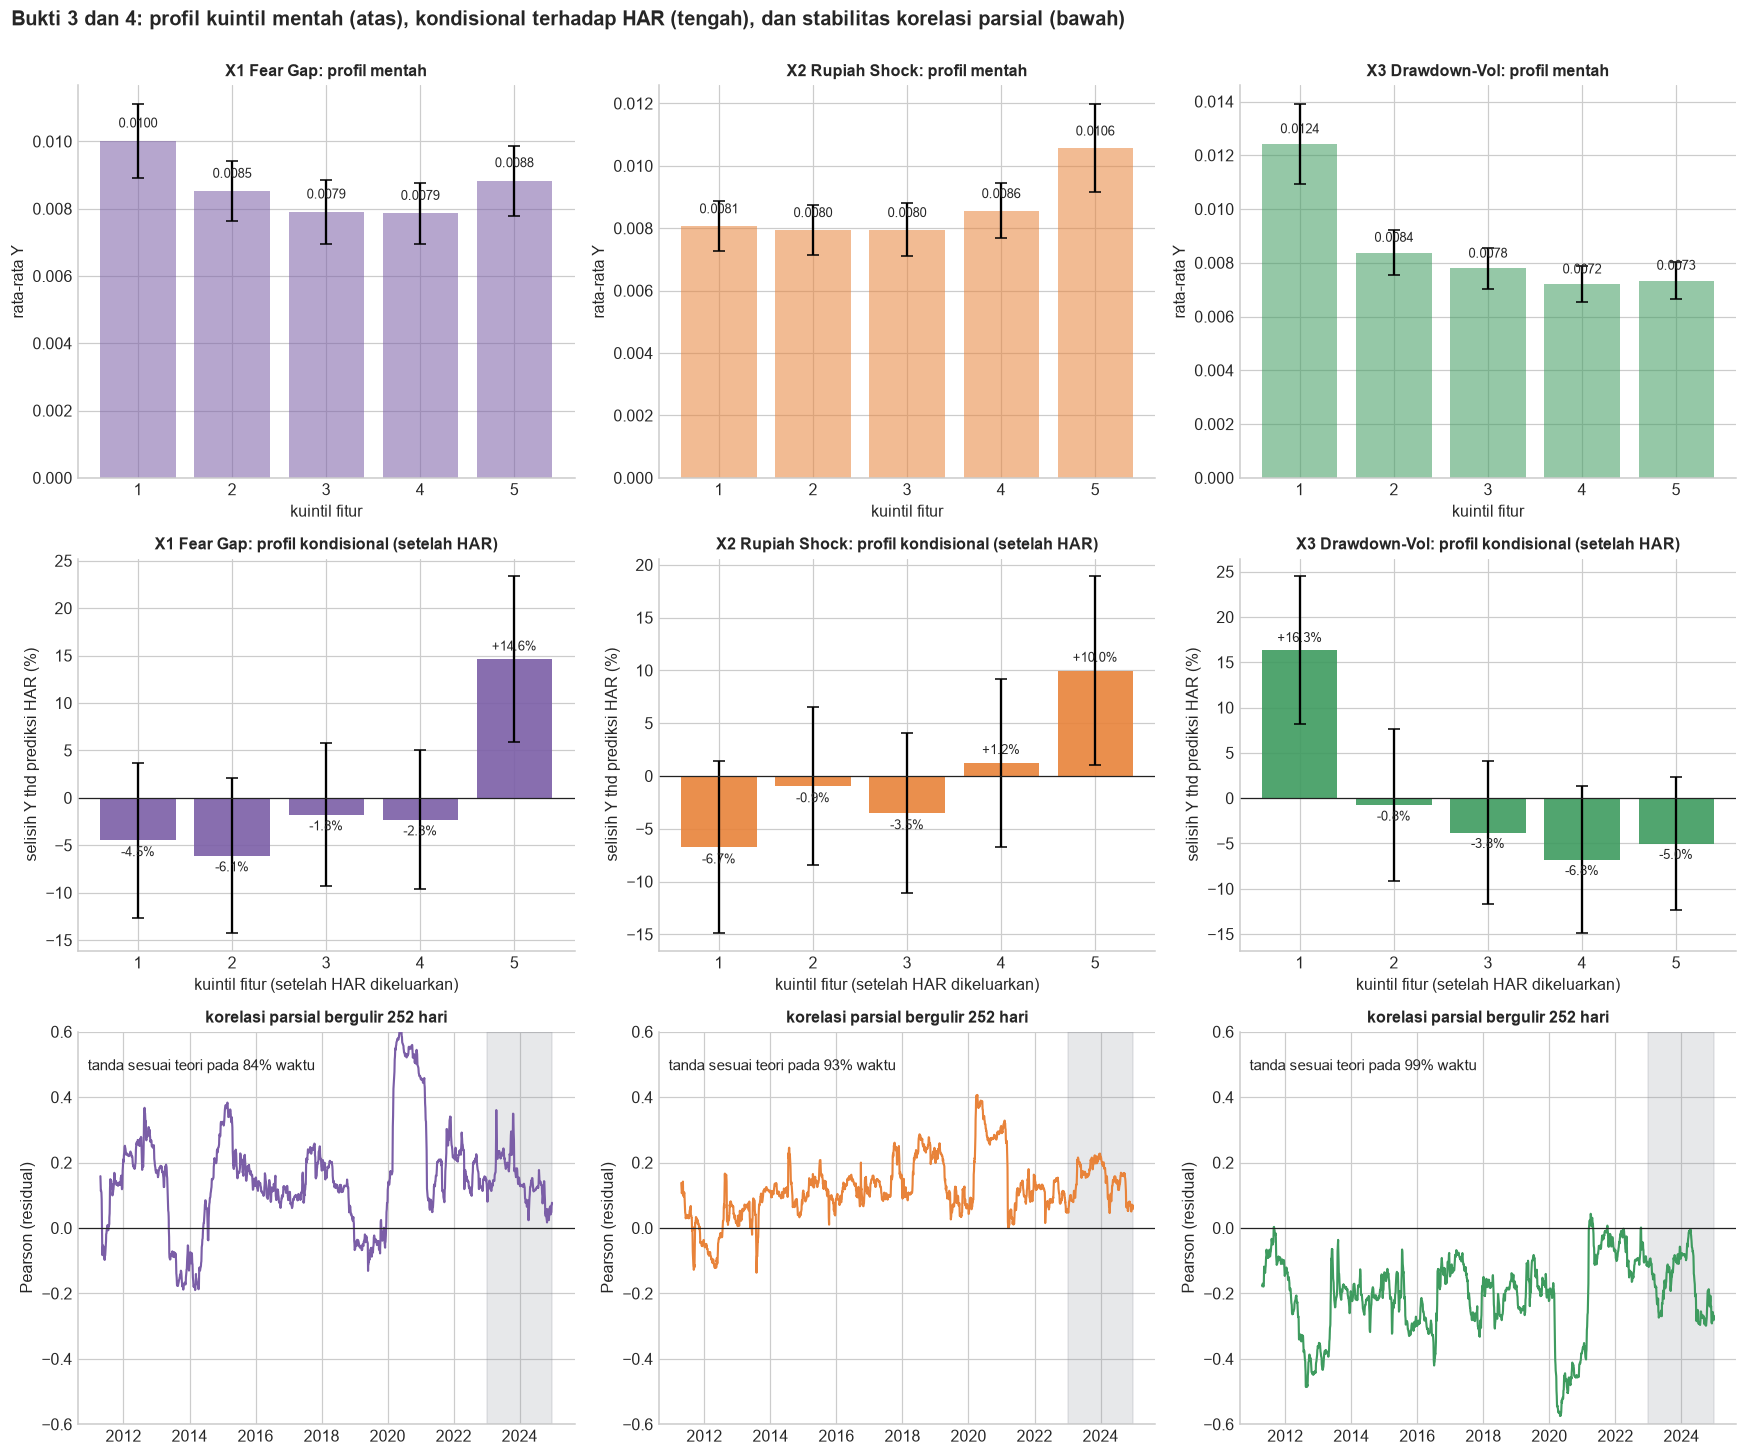

,Y_Q1_mentah,Y_Q5_mentah,rho_kuintil_mentah,selisih_Q5-Q1_kondisional_%,rho_kuintil_kondisional,%_waktu_tanda_sesuai_teori,korel_parsial_bergulir_min,korel_parsial_bergulir_maks
fitur,,,,,,,,
X1 Fear Gap,0.0100,0.0088,-0.40,+19.1,+0.80,84%,-0.19,+0.61
X2 Rupiah Shock,0.0081,0.0106,+0.70,+16.7,+0.90,93%,-0.14,+0.41
X3 Drawdown-Vol,0.0124,0.0073,-0.90,-21.3,-0.90,99%,-0.57,+0.04


In [19]:
# 10B Bukti 3 - 4

# Residual terhadap HAR: koefisien dipelajari dari data latih, lalu diterapkan ke seluruh baris (holdout = out-of-sample)
Xc_all = sm.add_constant(F.loc[idx, CORE])
lnY = np.log(yy + EPS_T)
fit_y = sm.OLS(lnY.loc[LATIH], Xc_all.loc[LATIH]).fit()
res_y = lnY - fit_y.predict(Xc_all)
res_x = {}
for c in [X1, X2, X3]:
    fx = sm.OLS(F.loc[LATIH, c], Xc_all.loc[LATIH]).fit()
    res_x[c] = F.loc[idx, c] - fx.predict(Xc_all)

titles = {X1: "X1 Fear Gap", X2: "X2 Rupiah Shock", X3: "X3 Drawdown-Vol"}
cols = {X1: PURPLE, X2: ORANGE, X3: GREEN}
expected = {X1: +1, X2: +1, X3: -1} # tanda hubungan terhadap volatilitas yang diharapkan secara ekonomi (kondisional)
fig, axes = plt.subplots(3, 3, figsize=(16, 13.2))
q_rows = []
for j, c in enumerate([X1, X2, X3]):
    # baris 1: profil kuintil raw
    ax = axes[0, j]
    bins = pd.qcut(F.loc[LATIH, c], 5, labels=False, duplicates="drop")
    g = yy.loc[LATIH].groupby(bins); m = g.mean(); se = g.std() / np.sqrt(g.size() / 5)
    ax.bar(m.index + 1, m.values, color=cols[c], alpha=0.55, yerr=1.96 * se.values, capsize=4)
    for k, v in zip(m.index + 1, m.values): ax.text(k, v + 0.0004, f"{v:.4f}", ha="center", fontsize=8.5)
    ax.set_title(f"{titles[c]}: profil mentah", fontsize=10.5); ax.set_ylabel("rata-rata Y"); ax.set_xlabel("kuintil fitur")
    raw_rho = stats.spearmanr(m.index.to_numpy(), m.to_numpy())[0]

    # baris 2: profil kuintil kodnisional
    ax = axes[1, j]
    rx, ry = res_x[c].loc[LATIH], res_y.loc[LATIH]
    b2 = pd.qcut(rx, 5, labels=False, duplicates="drop")
    g2 = ry.groupby(b2); m2 = g2.mean(); se2 = g2.std() / np.sqrt(g2.size() / 5)
    ax.bar(m2.index + 1, m2.values * 100, color=cols[c], alpha=0.9, yerr=1.96 * se2.values * 100, capsize=4)
    for k, v in zip(m2.index + 1, m2.values * 100): ax.text(k, v + (0.6 if v >= 0 else -0.6), f"{v:+.1f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=8.5)
    ax.axhline(0, color="#222", lw=0.8)
    ax.set_title(f"{titles[c]}: profil kondisional (setelah HAR)", fontsize=10.5); ax.set_ylabel("selisih Y thd prediksi HAR (%)"); ax.set_xlabel("kuintil fitur (setelah HAR dikeluarkan)")
    cond_rho = stats.spearmanr(m2.index.to_numpy(), m2.to_numpy())[0]

    # baris 3: korelasi parsial bergulir 252 hari
    ax = axes[2, j]
    roll = res_x[c].rolling(252).corr(res_y)
    ax.plot(roll.index, roll.values, color=cols[c], lw=1.4); ax.axhline(0, color="#222", lw=0.8)
    ax.axvspan(pd.Timestamp("2023-01-01"), idx.max(), color=GREY, alpha=0.2)
    share = ((roll.dropna() * expected[c]) > 0).mean() * 100
    ax.set_title("korelasi parsial bergulir 252 hari", fontsize=10.5); ax.set_ylabel("Pearson (residual)"); ax.set_ylim(-0.6, 0.6)
    ax.text(0.02, 0.93, f"tanda sesuai teori pada {share:.0f}% waktu", transform=ax.transAxes, fontsize=9.5, va="top")
    q_rows.append({"fitur": titles[c], "Y_Q1_mentah": m.iloc[0], "Y_Q5_mentah": m.iloc[-1], "rho_kuintil_mentah": raw_rho,
                   "selisih_Q5-Q1_kondisional_%": (m2.iloc[-1] - m2.iloc[0]) * 100, "rho_kuintil_kondisional": cond_rho,
                   "%_waktu_tanda_sesuai_teori": share, "korel_parsial_bergulir_min": roll.min(), "korel_parsial_bergulir_maks": roll.max()})
fig.suptitle("Bukti 3 dan 4: profil kuintil mentah (atas), kondisional terhadap HAR (tengah), dan stabilitas korelasi parsial (bawah)", x=0.01, ha="left", fontweight="bold", fontsize=13, y=1.0)
plt.tight_layout(); save_fig(fig, "dp_7.png"); plt.show()
q_tbl = pd.DataFrame(q_rows).set_index("fitur")
display(q_tbl.style.format({"Y_Q1_mentah": "{:.4f}", "Y_Q5_mentah": "{:.4f}", "rho_kuintil_mentah": "{:+.2f}", "selisih_Q5-Q1_kondisional_%": "{:+.1f}",
                            "rho_kuintil_kondisional": "{:+.2f}", "%_waktu_tanda_sesuai_teori": "{:.0f}%", "korel_parsial_bergulir_min": "{:+.2f}", "korel_parsial_bergulir_maks": "{:+.2f}"}))

>INTERPRETASI

1. Profil mentah dapat menyesatkan (baris atas). X1 tampak berbentuk "U" yang lemah (rata-rata $Y$ 0,0100 pada kuintil 1 dan 0,0088 pada kuintil 5), padahal hubungan kondisionalnya positif. X2 naik 31% dari kuintil 1 ke 5 (0,0081 -> 0,0106). X3 turun 41% (0,0124 -> 0,0073) dmna semakin dalam penurunan (kuintil 1), semakin tinggi volatilitas.

2. Profil kondisional (baris tengah) adalah bukti yang sesungguhnya. Setelah HAR dikeluarkan, kuintil tertinggi X1 menghasilkan $Y$ 14,6% di atas prediksi HAR, dan kuintil tertinggi X2 10,0% di atas, sedangkan kuintil terdalam X3 16,3% di atas. Selisih kuintil ekstrem: +19,1% (X1), +16,7% (X2), -21,3% (X3), dengan korelasi kuintil kondisional +0,8, +0,9, dan -0,9.

3. Hampir seluruh dampak terkonsentrasi di satu kuintil ekstrem. Kuintil lain hanya berkisar -7% sampai +1%. Model non-linear berbasis pohon sesuai karena mampu menangkap efek ambang, dan untuk Sistem Peringatan Dini ini bermakna bahwa sinyal paling berguna justru saat kondisi sedang ekstrem.
4. Stabilitas antar waktu (baris bawah). Tanda korelasi parsial bergulir sesuai teori pada 99% waktu untuk X3, 93% untuk X2, dan 84% untuk X1. X1 paling tidak stabil (sempat berbalik tanda sekitar 2013-2014 dan 2019) dan paling kuat saat krisis 2020 (mencapai sekitar 0,6). Pada periode *holdout* (abu-abu) ketiga fitur tetap berada pada sisi yang diharapkan.X

Gambar disimpan: xLain-Lain/img/dp_8.png


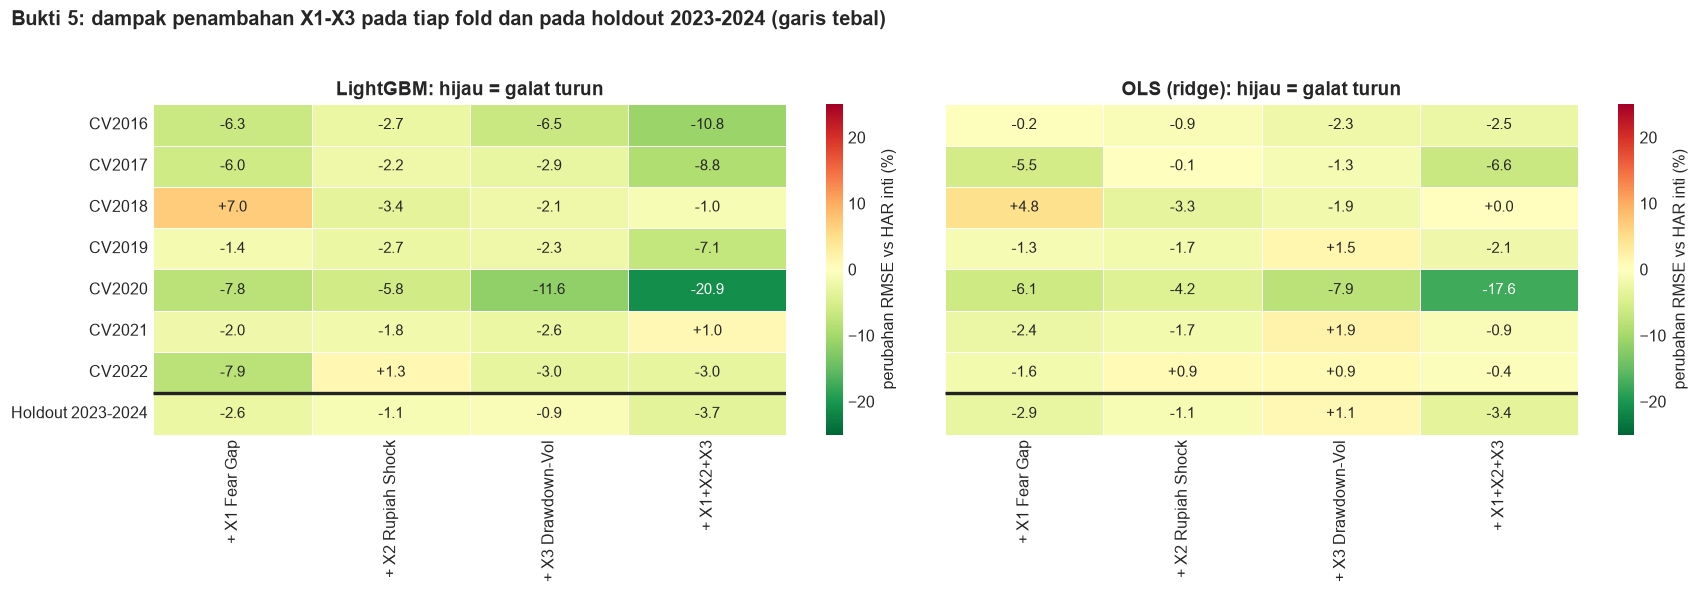

Jumlah fold CV (dari 7) yang membaik dengan X1+X2+X3: LightGBM = 6 | OLS = 6
Gambar disimpan: xLain-Lain/img/dp_9.png


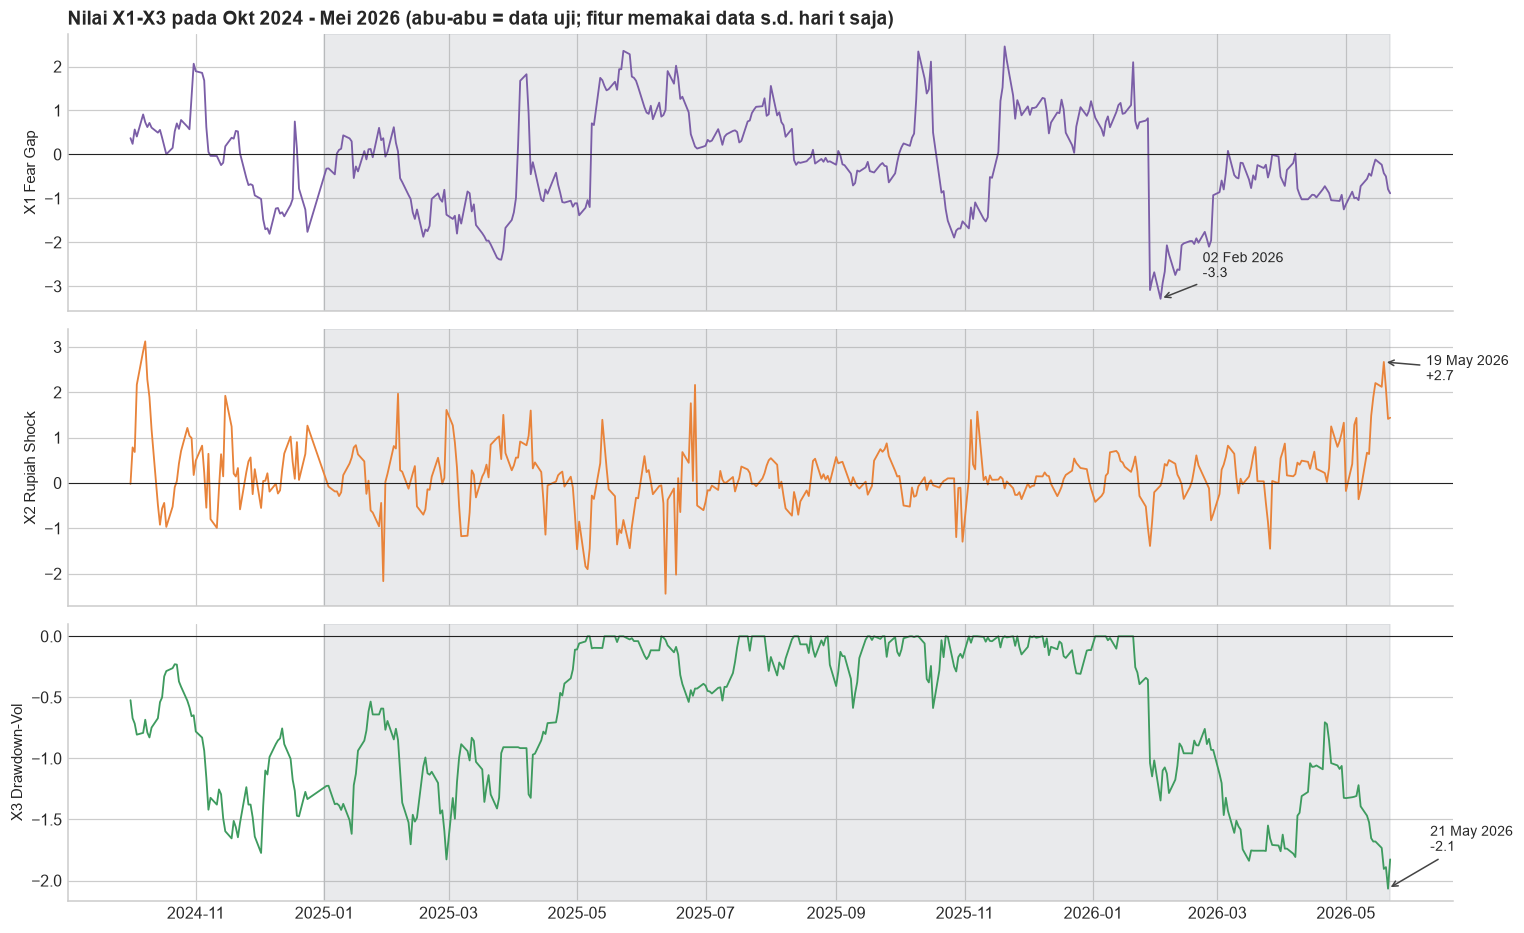

In [20]:
# 10C Bukti 5

variants = {"+ X1 Fear Gap": [X1], "+ X2 Rupiah Shock": [X2], "+ X3 Drawdown-Vol": [X3], "+ X1+X2+X3": [X1, X2, X3]}
base_all = {n: run_cv(F[CORE].loc[idx], yy, all_folds, mk[n], "log") for n in ("OLS", "LGBM")}
rows = []
for vname, fs in variants.items():
    for n in ("OLS", "LGBM"):
        pn = run_cv(F[CORE + fs].loc[idx], yy, all_folds, mk[n], "log")
        for f in all_folds:
            rb = metrics(yy.loc[f["val"]], base_all[n].loc[f["val"]])["RMSE"]; rn = metrics(yy.loc[f["val"]], pn.loc[f["val"]])["RMSE"]
            rows.append({"varian": vname, "model": n, "fold": f["name"], "dRMSE%": (rn / rb - 1) * 100})
fold_tbl = pd.DataFrame(rows)
piv = fold_tbl[fold_tbl["model"] == "LGBM"].pivot(index="fold", columns="varian", values="dRMSE%").loc[[f["name"] for f in all_folds], list(variants)]
pivo = fold_tbl[fold_tbl["model"] == "OLS"].pivot(index="fold", columns="varian", values="dRMSE%").loc[[f["name"] for f in all_folds], list(variants)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), sharey=True)
for ax, tb, ttl in [(axes[0], piv, "LightGBM"), (axes[1], pivo, "OLS (ridge)")]:
    sns.heatmap(tb, annot=True, fmt="+.1f", cmap="RdYlGn_r", center=0, vmin=-25, vmax=25, linewidths=0.5, ax=ax,
                cbar_kws={"label": "perubahan RMSE vs HAR inti (%)"}, annot_kws={"fontsize": 9.5})
    ax.set_title(f"{ttl}: hijau = galat turun"); ax.set_xlabel(""); ax.set_ylabel("")
    ax.hlines(len(all_folds) - 1, *ax.get_xlim(), color="#222", lw=2.2)
    ax.grid(False)
fig.suptitle("Bukti 5: dampak penambahan X1-X3 pada tiap fold dan pada holdout 2023-2024 (garis tebal)", x=0.01, ha="left", fontweight="bold", fontsize=13.2, y=1.03)
plt.tight_layout(); save_fig(fig, "dp_8.png"); plt.show()
print("Jumlah fold CV (dari 7) yang membaik dengan X1+X2+X3: LightGBM =", int((piv.iloc[:-1]["+ X1+X2+X3"] < 0).sum()), "| OLS =", int((pivo.iloc[:-1]["+ X1+X2+X3"] < 0).sum()))

fig, axes = plt.subplots(3, 1, figsize=(14, 8.6), sharex=True)
seg = F.loc["2024-10-01":, [X1, X2, X3]]
for ax, c in zip(axes, [X1, X2, X3]):
    ax.plot(seg.index, seg[c], color=cols[c], lw=1.2)
    ax.axhline(0, color="#222", lw=0.7); ax.axvspan(TEST_START, seg.index.max(), color=GREY, alpha=0.18)
    ax.set_ylabel(X_NAMES[c], fontsize=9.5)
    top = seg[c].loc[TEST_START:]
    ext = top.abs().idxmax()
    ax.annotate(f"{ext:%d %b %Y}\n{top[ext]:+.1f}", xy=(ext, top[ext]), xytext=(ext + pd.Timedelta(days=20), top[ext] * 0.85), fontsize=9, arrowprops=dict(arrowstyle="->", color="#444"))
axes[0].set_title("Nilai X1-X3 pada Okt 2024 - Mei 2026 (abu-abu = data uji; fitur memakai data s.d. hari t saja)", loc="left")
plt.tight_layout(); save_fig(fig, "dp_9.png"); plt.show()

>INTERPRETASI

1. Penambahan X1+X2+X3 membaik pada 6 dari 7 fold CV untuk kedua model. Satu-satunya fold yang tidak membaik adalah 2021 pada LightGBM (+1,0%) dan 2018 pada OLS (≈ 0,0%).
2. Manfaat terbesar justru terjadi saat krisis dimana fold 2020 turun 20,9% (LightGBM) dan 17,6% (OLS), diikuti 2016 (-10,8%), 2017 (-8,8%), dan 2019 (-7,1%). Ini yang diharapkan dari sebuah sistem peringatan dini. Nilai tambahnya paling besar ketika risikonya paling besar.
3. Satu kelemahan yang kami catat adalah X1 sendirian justru memperburuk fold 2018 (+7,0% LightGBM; +4,8% OLS). Fold itu adalah periode tekanan pasar negara berkembang, ketika ketakutan global dan tekanan lokal bergerak berbeda. Ini konsisten dengan stabilitas X1 yang paling rendah (84%).

4. Pada *holdout* manfaatnya lebih kecil (-3,7% LightGBM, -3,4% OLS).

5. Fitur merespons dengan wajar tanpa memakai $Y$: X3 bergerak ke wilayah dalam (hingga -2,1 pada 21 Mei 2026), X2 mencapai +2,7 pada 19 Mei 2026, dan X1 turun tajam hingga -3,3 pada 2 Februari 2026. Nilai X1 yang sangat negatif berarti gejolak lokal yang sudah terjadi jauh melampaui ketakutan global (VIX), yaitu pola guncangan yang bersumber di dalam negeri.

### ****11. Pemeriksaan Pada Blok Holdout 2023 - 2024****

Mengapa ini penting? Seluruh seleksi pada bagian 9 memakai fold CV 2016 - 2022. Wajar bila fitur terpilih tampak baik di sana karena kami memilihnya berdasarkan fold tersebut. *Holdout* 2023 - 2024 tidak pernah dipakai untuk memilih apa pun, sehingga hasil di sini adalah ukuran generalisasi yang tidak bias. Pada blok ini model dilatih pada seluruh data latih (2010 - 2022, dikurangi *purge*).




In [21]:
tr_h, va_h = holdout["train"], holdout["val"]
yh = y.loc[va_h]
preds = {"Naif (rv5 = Y_(t-5))": F.loc[va_h, "rv5"]}
for name, feats, mf in [("HAR inti, OLS", CORE, make_ols), ("HAR + X1-X3, OLS", CORE_X, make_ols),
                        ("HAR inti, LightGBM", CORE, make_lgbm), ("HAR + X1-X3, LightGBM", CORE_X, make_lgbm)]:
    p, _ = fit_predict(F.loc[tr_h, feats], y.loc[tr_h], F.loc[va_h, feats], mf, "log")
    preds[name] = pd.Series(p, index=va_h)
hold_tbl = pd.DataFrame({k: metrics(yh, v) for k, v in preds.items()}).T
hold_tbl["RMSE vs naif"] = (hold_tbl["RMSE"] / hold_tbl.loc["Naif (rv5 = Y_(t-5))", "RMSE"] - 1) * 100
display(hold_tbl.style.format({"RMSE": "{:.5f}", "MAE": "{:.5f}", "QLIKE": "{:.4f}", "RMSE vs naif": "{:+.1f}%"}))

for n_, a_, b_ in [("OLS", "HAR inti, OLS", "HAR + X1-X3, OLS"), ("LightGBM", "HAR inti, LightGBM", "HAR + X1-X3, LightGBM")]:
    for loss in ("se", "ae", "qlike"):
        dm = dm_test(yh, preds[a_], preds[b_], loss)
        print(f"DM holdout, {n_}, HAR inti vs +X1-X3, kerugian {loss:>5}: rata-rata selisih {dm[0]:+.3e}, t = {dm[1]:+.2f}, p = {dm[2]:.3f}")

,RMSE,MAE,QLIKE,RMSE vs naif
Naif (rv5 = Y_(t-5)),0.00403,0.00297,1.6264,+0.0%
"HAR inti, OLS",0.00323,0.00260,0.4700,-19.7%
"HAR + X1-X3, OLS",0.00312,0.00249,0.4381,-22.4%
"HAR inti, LightGBM",0.00331,0.00262,0.5027,-17.7%
"HAR + X1-X3, LightGBM",0.00319,0.00247,0.4703,-20.7%


DM holdout, OLS, HAR inti vs +X1-X3, kerugian    se: rata-rata selisih +6.967e-07, t = +1.45, p = 0.147
DM holdout, OLS, HAR inti vs +X1-X3, kerugian    ae: rata-rata selisih +1.010e-04, t = +1.40, p = 0.162
DM holdout, OLS, HAR inti vs +X1-X3, kerugian qlike: rata-rata selisih +3.189e-02, t = +1.56, p = 0.120
DM holdout, LightGBM, HAR inti vs +X1-X3, kerugian    se: rata-rata selisih +7.962e-07, t = +2.20, p = 0.028
DM holdout, LightGBM, HAR inti vs +X1-X3, kerugian    ae: rata-rata selisih +1.475e-04, t = +2.65, p = 0.008
DM holdout, LightGBM, HAR inti vs +X1-X3, kerugian qlike: rata-rata selisih +3.244e-02, t = +1.88, p = 0.060


>INTERPRETASI (*Holdout* 2023 - 2024, 517 baris, tidak dipakai untuk memilih apa pun.)

1. Semua model mengalahkan naif dengan jelas.HAR inti OLS -19,7%, HAR + X1-X3 OLS -22,4%, HAR inti LightGBM -17,7%, HAR + X1-X3 LightGBM -20,7%.

2. Penambahan X1-X3 membaik pada kedua model, tetapi kecil dan tidak seragam signifikansinya. RMSE turun 3,4% (OLS) dan 3,6% (LightGBM); QLIKE turun 6,8% dan 6,4%. Pada LightGBM perbaikannya signifikan: DM $p=0{,}028$ (galat kuadrat), 0,008 (galat absolut), 0,060 (QLIKE). Pada OLS arahnya sama tetapi belum signifikan ($p=0{,}12$ sampai 0,16).

3. Mengapa lebih kecil daripada di CV (-9,6% sampai -12,5%)? Dua alasan yang dapat dibuktikan adlah *bias seleksi* dimana fitur dipilih berdasarkan fold CV sehingga tampak lebih baik di sana, dan *holdout* adalah ukuran jujur; *holdout* adalah periode paling tenang (hanya 1,5% hari di atas P90), sedangkan manfaat X1-X3 terbesar justru pada krisis (fold 2020: -20,9%).

4. Pada *holdout* OLS linear sedikit lebih baik dari LightGBM (0,00312 vs 0,00319). Tahap 4 akan menguji apakah LightGBM yang di-*tuning* dan diregularisasi mampu unggul, termasuk di fold krisis; pemilihan satu model akhir harus berdasarkan seluruh fold.

### ****12. Pemeriksaan Pergeseran Rezim Setelah Rekayasa Fitur****

Tahap 2 menunjukkan bahwa level mentah membedakan periode uji dari periode latih dengan AUC = 1,000, sedangkan fitur volatilitas *trailing* berada di 0,874. Pertanyaannya sekarang, apakah fitur hasil rekayasa kita (khususnya komposit yang diukur dalam satuan volatilitasnya sendiri) lebih tahan terhadap pergeseran itu? Kami mengulang *adversarial validation* yang sama pada set fitur final.

,AUC,std
[NB2] Level mentah,1.000,0.000
[NB2] Volatilitas trailing,0.874,0.037
[NB2] Perubahan harian,0.682,0.016
HAR inti (3 fitur),0.918,0.013
X1-X3 saja,0.734,0.044
HAR + X1-X3 (6 fitur),0.949,0.017
Semua fitur kandidat non-level,1.000,0.000
Semua fitur kandidat + level makro,1.000,0.000


,importance,keluarga
us_chg63,0.158,Suku bunga
log_usd_rv22,0.097,Kurs
log_gold_rv22,0.065,Komoditas
rv66,0.062,HAR / volatilitas IHSG
log_rv66,0.060,HAR / volatilitas IHSG
bi_chg63,0.043,Suku bunga
bi_days_since,0.039,Suku bunga
log_usd_rv5,0.039,Kurs


Gambar disimpan: xLain-Lain/img/dp_10.png


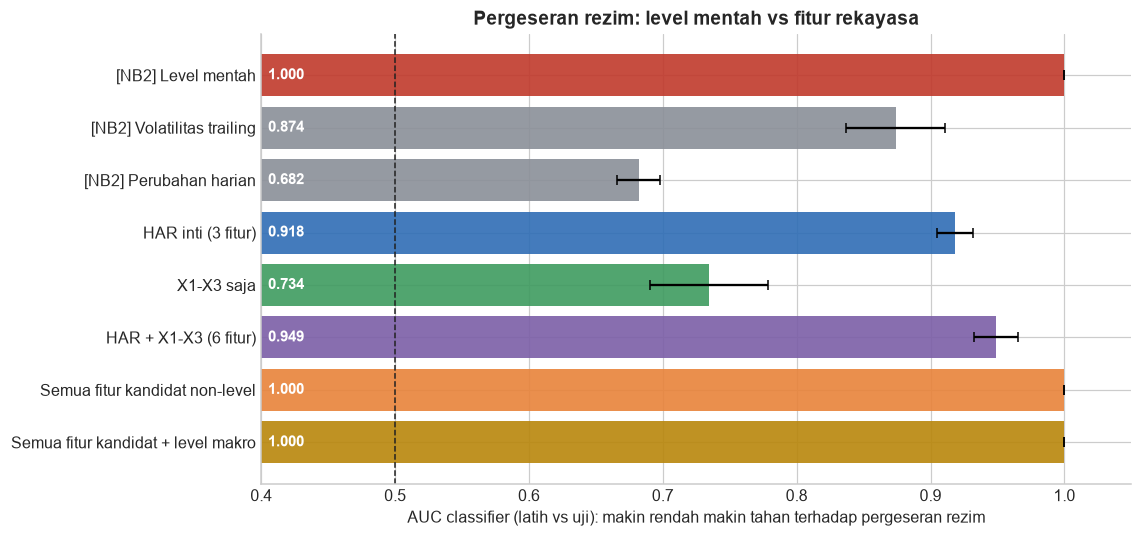

In [22]:
rows_all = F.index[F.index >= VALID_FROM]
y_adv = (rows_all >= TEST_START).astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
clf = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5, random_state=SEED, n_jobs=1)

sets = {
    "HAR inti (3 fitur)": CORE,
    "X1-X3 saja": [X1, X2, X3],
    "HAR + X1-X3 (6 fitur)": CORE_X,
    "Semua fitur kandidat non-level": [c for c in ALL_FEATS if FAMILY[c] != "Level makro (kontrol negatif)"],
    "Semua fitur kandidat + level makro": ALL_FEATS,
}
res = {}
for name, fs in sets.items():
    X = F.loc[rows_all, fs]; ok = X.notna().all(axis=1)
    sc = cross_val_score(clf, X[ok], y_adv[ok.values], cv=cv, scoring="roc_auc")
    res[name] = (sc.mean(), sc.std())
adv = pd.DataFrame(res, index=["AUC", "std"]).T
ref = pd.DataFrame({"AUC": [1.000, 0.874, 0.682], "std": [0.000, 0.037, 0.016]},
                   index=["[NB2] Level mentah", "[NB2] Volatilitas trailing", "[NB2] Perubahan harian"])
adv_all = pd.concat([ref, adv])
display(adv_all.style.format("{:.3f}"))

# fiture mana yang paling membedakan uji dari latih pada set "semua non-level"?
fs_all = sets["Semua fitur kandidat non-level"]
Xa = F.loc[rows_all, fs_all]; oka = Xa.notna().all(axis=1)
clf2 = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5, random_state=SEED, n_jobs=1).fit(Xa[oka], y_adv[oka.values])
culprit = pd.Series(clf2.feature_importances_, index=fs_all).sort_values(ascending=False).head(8)
display(culprit.rename("importance").to_frame().assign(keluarga=[FAMILY[c] for c in culprit.index]).style.format({"importance": "{:.3f}"})
        .set_caption("Fitur 'non-level' yang paling membedakan periode uji dari periode latih"))

fig, ax = plt.subplots(figsize=(10.5, 5))
colors = [RED] + [GREY, GREY] + [BLUE, GREEN, PURPLE, ORANGE, "#B8860B"]
bars = ax.barh(adv_all.index[::-1], adv_all["AUC"][::-1], xerr=adv_all["std"][::-1], color=colors[::-1][:len(adv_all)], alpha=0.9, capsize=3)
ax.axvline(0.5, color="#222", ls="--", lw=1)
for b, v in zip(bars, adv_all["AUC"][::-1]):
    ax.text(0.405, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", ha="left", color="white", fontweight="bold", fontsize=10)
ax.set_xlim(0.4, 1.05); ax.set_xlabel("AUC classifier (latih vs uji): makin rendah makin tahan terhadap pergeseran rezim")
ax.set_title("Pergeseran rezim: level mentah vs fitur rekayasa"); plt.tight_layout(); save_fig(fig, "dp_10.png"); plt.show()

>INTERPRETASI

1. X1-X3 saja jauh lebih tahan pergeseran rezim: AUC 0,734, dibanding level mentah 1,000. Komposit yang diukur dalam satuan volatilitasnya sendiri memang mengurangi pergeseran.
2. HAR inti memiliki AUC 0,918 dan HAR + X1-X3 0,949. Volatilitas IHSG 22 dan 66 hari pada periode uji memang lebih tinggi (Tahap 2: 23% hari di atas P90 vs 10%), dan itu justru informasi yang kami inginkan model tangkap. Pergeseran ini tidak boleh dhilangkan, ia harus diwaspadai dan diuji dengan fold bertekanan.
3. Semua fitur kandidat non-level mencapai AUC 1,000, dan penyebabnya jelas karena us_chg63 (importance 0,158), log_usd_rv22 (0,097), log_gold_rv22 (0,065), volatilitas 66 hari, serta fitur perubahan suku bunga. Fitur-fitur itulah yang dapat mengenali periode uji. Dengan kata lain, fitur yang kami keluarkan dari set final adalah fitur yang paling rawan terhadap pergeseran, dan ini selaras dengan hasil penyaringan (log_usd_rv22 merugikan +3,8%) dan forward seelction (tidak ada fitur suku bunga yang terpilih).
4. Keterbatasan metode (sama seperti Tahap 2): lipatan diacak sehingga hari berdekatan terpisah antar lipatan, menaikkan AUC pada semua set. Angkanya dibaca sebagai urutan relatif, bukan nilai absolut.

### ****13. Perakitan Keluaran dan Serah Terima ke Tahap 4****

Sel terakhir merakit tiga set fitur untuk pemodelan dan menyimpan seluruh keluaran. Tiga set tersebut sengaja dirancang berjenjang agar Tahap 4 dapat membuktikan nilai tambah tiap lapisan:

| Set | Isi | Tujuan |
|---|---|---|
| S1 · HAR | log_rv5, log_rv22, log_rv66 | Benchmark struktur ekonometrik |
| S2 · HAR + X1-X3 | S1 + vrp_z126, usd_z5, dd60_vol | Jawaban langsung Task 1 |
| S3 · Diperluas** | S2 + fitur hasil forward selection yang belum ada | Kandidat model akhir |

Fitur level (spread, cpi_level) tidak disertakan pada set mana pun.

In [23]:
S1 = CORE
S2 = CORE_X
S3 = list(dict.fromkeys(CORE_X + FWD_SELECTED))
FEATURE_SETS = {"S1_HAR": S1, "S2_HAR_X1X3": S2, "S3_diperluas": S3}

role = pd.Series("uji", index=F.index)
role[F.index < VALID_FROM] = "pemanasan"
role[(F.index >= VALID_FROM) & (F.index <= "2022-12-31")] = "latih"
role[(F.index > "2022-12-31") & (F.index <= TRAIN_END)] = "validasi_holdout"
out = F[ALL_FEATS + FLAGS].copy()
out.insert(0, "peran", role)
out.insert(0, TARGET, y)
out["label_tak_pasti"] = LABEL_UNCERTAIN
out.to_csv(CLEAN_DIR / "features_daily.csv", index_label="Date")
with open(CLEAN_DIR / "feature_sets.json", "w") as fh:
    json.dump({"VALID_FROM": str(VALID_FROM.date()), "X": {"X1": X1, "X2": X2, "X3": X3}, "sets": FEATURE_SETS}, fh, indent=2)

summ = pd.DataFrame({"set": list(FEATURE_SETS), "jumlah_fitur": [len(v) for v in FEATURE_SETS.values()], "fitur": [", ".join(v) for v in FEATURE_SETS.values()]})
display(summ.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
print("\nPeran baris:"); display(role.value_counts().rename("jumlah").to_frame().T)
print("Keluaran tersimpan: Dataset/Clean/features_daily.csv, feature_catalog.csv, feature_sets.json, splits.csv; Catatan/hypothesis_verdict.csv")
assert out.loc[out["peran"] == "uji", ALL_FEATS].drop(columns=[]).isna().mean().max() < 0.02, "Fitur data uji memiliki terlalu banyak NaN"

set,jumlah_fitur,fitur
S1_HAR,3,"log_rv5, log_rv22, log_rv66"
S2_HAR_X1X3,6,"log_rv5, log_rv22, log_rv66, vrp_z126, usd_z5, dd60_vol"
S3_diperluas,7,"log_rv5, log_rv22, log_rv66, vrp_z126, usd_z5, dd60_vol, ihsg_ret22"



Peran baris:


,latih,validasi_holdout,uji,pemanasan
jumlah,3303,517,359,87


Keluaran tersimpan: Dataset/Clean/features_daily.csv, feature_catalog.csv, feature_sets.json, splits.csv; Catatan/hypothesis_verdict.csv


>INTERPRETASI

1. Tiga set fitur berjenjang telah dirakit: S1 (HAR, 3 fitur), S2 (HAR + X1-X3, 6 fitur), dan S3 (S2 + ihsg_ret22, 7 fitur). Pemodelan di Tahap 4 akan membuktikan nilai tambah tiap lapisan dengan protokol yang sama.
2. Pembagian peran baris: 3.303 latih, 517 validasi (*holdout*), 359 uji, dan 87 baris pemanasan (total 4.266). Setiap baris pada features_daily.csv memuat kolom peran dan label_tak_pasti, sehingga tidak ada ambiguitas tentang siapa dipakai untuk apa.
3. Fitur level makro (spread, cpi_level) tidak ada pada set mana pun, sesuai bukti pada Bagian 9B.

### ****Rasionalitas Bisnis dan Finansial X1 - X3 (Jawaban Task 1)****

| Pertanyaan | Jawaban |
|---|---|
| Apa idenya? | Membandingkan ketakutan yang diekspektasikan pasar global (VIX) dengan gejolak yang sudah terjadi di IHSG. |
| Rumus | $X_1 = z_{126}\Big(\ln\dfrac{VIX_t/100}{\sqrt{252}} - \ln RV^{IHSG}_{22,t}\Big)$ |
| Mengapa digabungkan dan ditransformasi? | VIX dinyatakan dalam persen tahunan, sedangkan $RV$ IHSG adalah simpangan baku harian; keduanya dibuat sebanding dengan membagi VIX dengan $100\sqrt{252}$. Rasio dalam logaritma membuatnya bebas skala. *Z-score* 126 hari membuatnya relatif terhadap kondisi enam bulan terakhir, sehingga sebanding antara rezim tenang dan krisis. |
| Hipotesis ekonomi (H1) | Bila ketakutan global melampaui gejolak lokal yang sudah terjadi, pasar domestik belum menyerap guncangan itu, sehingga volatilitas IHSG akan menyusul naik. Ini adaptasi dari *variance risk premium* (Whaley, 2000; Bollerslev, Tauchen & Zhou, 2009). |
| Bukti kuantitatif | Korelasi parsial +0,11 ($p=0{,}006$); kuintil tertinggi menghasilkan $Y$ 14,6% di atas prediksi HAR; DM $p=0{,}003$ (CV); ablasi: RMSE naik 4,0% (OLS) dan 6,2% (LightGBM) bila dilepas. |
| Batas klaim | Hanya bermakna di dalam model yang memuat HAR (korelasi mentahnya negatif karena efek penekanan). Tanda berbalik pada fold 2018 dan stabil 84% waktu. |

### ****X2 · *Rupiah Shock* (usd_z5): Tekanan Arus Modal Melalui Kurs****

| Pertanyaan | Jawaban |
|---|---|
| Apa idenya? | Mengukur seberapa besar rupiah melemah dalam 5 hari, dalam satuan volatilitas kurs itu sendiri. |
| Rumus | $X_2 = \dfrac{USDIDR_t/USDIDR_{t-5}-1}{\sigma^{126}_{USDIDR}\sqrt{5}}$ |
| Mengapa ditransformasi? | Pelemahan 1% bermakna sangat berbeda ketika kurs tenang dan ketika kurs bergejolak. Pembagian dengan volatilitas harian 126 hari memberi ukuran "berapa simpangan baku guncangan ini", sehingga sebanding antar rezim; juga mengatasi perbedaan skala akibat tren naik kurs jangka panjang. |
| Hipotesis ekonomi (H2) | Pelemahan tajam rupiah mengurangi imbal hasil investor asing dalam mata uang dasar dan memicu arus modal keluar serta tekanan jual ekuitas, sehingga volatilitas IHSG naik (Forbes & Warnock, 2012; Rey, 2013). |
| Hasil pengujian hipotesis | Saluran kurs terdukung (usd_ret5 -4,4%, $p=0{,}010$). Interaksi dengan selisih suku bunga BI-The Fed (rsi, rsi2) tidak memperbaiki fitur, sehingga bagian *carry* dari hipotesis kami ditolak dan tidak dimasukkan. |
| Bukti kuantitatif | Korelasi parsial +0,11 ($p=0{,}009$); kuintil tertinggi +10,0% di atas prediksi HAR; tanda sesuai teori 93% waktu. |
| Batas klaim | Kontributor terkecil dari ketiganya: bila dilepas, RMSE hanya naik 0,7% sampai 1,7% (tidak signifikan secara individual). Namun ia pelengkap terbaik yang tersisa setelah X1 dan X3, dan mewakili saluran yang berbeda. |

### X3 · *Drawdown-Vol* (dd60_vol): Kedalaman Penurunan dalam Satuan Volatilitas Normal

| Pertanyaan | Jawaban |
|---|---|
| Apa idenya? | Mengukur berapa "simpangan baku" IHSG sudah turun dari puncak 60 harinya. |
| Rumus | $X_3 = \dfrac{IHSG_t / \max_{60}(IHSG) - 1}{RV^{IHSG}_{66,t}\sqrt{60}}$ |
| Mengapa ditransformasi? | Penurunan 5% sangat berbeda artinya di pasar yang biasanya bergerak 0,5% per hari dan di pasar yang biasa bergerak 1,5% per hari. Pembagian dengan $RV_{66}\sqrt{60}$ (volatilitas yang diharapkan selama 60 hari) menormalkan kedalaman penurunan terhadap volatilitas normalnya. |
| Hipotesis ekonomi (H4) | Penurunan harga yang dalam menaikkan leverage keuangan perusahaan dan aversi risiko investor, sehingga volatilitas naik. Ini *leverage effect* (Black, 1976; Engle & Ng, 1993). |
| Bukti kuantitatif | Fitur tunggal terkuat: RMSE -7,4% (LightGBM, membaik pada 7 dari 7 fold); korelasi parsial -0,16 ($p<10^{-4}$); kuintil terdalam +16,3% di atas prediksi HAR; tanda sesuai teori 99% waktu; ablasi: RMSE naik 4,1% sampai 5,3% bila dilepas. |
| Batas klaim | Pada *holdout* tenang, perbaikan fitur ini sendirian hanya -0,9% (LightGBM) dan +1,1% (OLS); nilainya terbesar pada krisis (fold 2020: -11,6% LightGBM). |

### Ringkasan lintas-saluran

Ketiga fitur mewakili tiga saluran berbeda (sentimen global, kurs/arus modal, asimetri domestik), seluruhnya terstandardisasi dalam satuan volatilitasnya sendiri, dan seluruhnya diuji kontribusi marginalnya di atas struktur HAR, bukan sekadar dikorelasikan. Bersama-sama mereka menurunkan RMSE validasi CV 9,6% (OLS) dan 12,5% (LightGBM) (6 dari 7 fold), dan RMSE *holdout* 3,4% sampai 3,6%, dengan manfaat terbesar pada krisis (-20,9% pada fold 2020).

## ****Kesimpulan dan Langkah Berikutnya****

Yang dibuktikan notebook ini

| # | Klaim | Bukti |
|---|---|---|
| 1 | Pembersihan bersifat kausal dan efektif | *Return* USDIDR terbesar 902,9% → 5,9%; 16 -> 0 hari dengan *return* harian di atas 10% |
| 2 | Fitur selaras dengan definisi target | Kalender penuh: 99,92% cocok persis; rv5 ≡ $Y_{t-5}$ ($7{,}2\times10^{-10}$) |
| 3 | Tidak ada pengacakan; pemisahan kronologis dengan *purge* | 8 fold lulus uji integritas; 7 fold CV mencakup 2018, 2020, 2022 |
| 4 | Praproses hanya di-*fit* pada data latih | scaler.mean_ ≡ rata-rata latih; kebocoran jika *fit* seluruh data: 1,2-5,6% simpangan baku |
| 5 | Fitur hari $t$ tidak memakai informasi $t+1$ | 60 fitur × 46 tanggal: 0 kegagalan; kontrol negatif gagal 46/46; uji perturbasi lulus |
| 6 | Kebocoran memberi kinerja palsu | $Y_{t-1}$ menurunkan RMSE LightGBM 38% secara palsu |
| 7 | X1-X3 menambah informasi di atas HAR | CV: -9,6% (OLS), -12,5% (LightGBM); *holdout*: -3,4%/-3,6%; 6 dari 7 fold |
| 8 | Pemilihan fitur tidak sepihak | Seleksi maju independen memilih ketiganya plus ihsg_ret22 |
| 9 | Hipotesis diuji, bukan dibenarkan | 4 terdukung, 1 sebagian, 2 tidak terdukung; bagian *carry* H2 ditolak |

**Disini kami menyadari keterbatasan kami, yaitu:**

1. Kontribusi marginal X2 kecil (≈ 1%) dan tidak signifikan secara individual. kontribusi terbesar berasal dari X1 dan X3.
2. X1 tidak stabil pada fold 2018 dan hanya bermakna bersama HAR.
3. Pada *holdout* tenang, perbaikan hanya 3,4-3,6% dan signifikan untuk LightGBM tetapi belum untuk OLS.
4. Pemilihan fitur dilakukan pada 54 kandidat; *p-value* dipakai untuk pemeringkatan, dan klaim tak bias hanya dari *holdout*.
5. Pergeseran rezim volatilitas pada periode uji tidak dapat dihilangkan oleh rekayasa fitur (AUC 0,92-0,95); ia harus diwaspadai melalui fold bertekanan.

**Langkah berikutnya: Tahap 4 (Modeling)**

1. Membandingkan kandidat model pada S1, S2, S3 dengan protokol yang sama: baseline naif, HAR-OLS, GARCH(1,1) / GJR-GARCH, LightGBM, XGBoost, dan Random Forest.
2. Memilih satu model akhir berdasarkan seluruh fold (bukan satu blok tenang), dengan alasan yang dapat dipertahankan.
3. *Hyperparameter tuning* sistematis (Optuna) hanya pada fold CV; *holdout* disentuh satu kali.
4. Latih ulang pada seluruh data berlabel dan menghasilkan 359 prediksi data uji.